# Not All Students Below the Mathematics Baseline Are the Same: A Threshold-Specific Analysis of PISA 2025 Indonesia

## Reproducible analysis notebook

This notebook reproduces every estimate, table and figure reported in the article, from the public PISA 2025 data files to the final output. Each numbered section corresponds to a part of the manuscript:

| Section | What it does | Manuscript |
|---|---|---|
| 0 | Settings and software | Methods: Analysis |
| 1 | Load the Indonesian student and school data | Methods: Data and sample |
| 2 | Survey design tools: weights, BRR-Fay variance, plausible-value pooling | Methods: Analysis |
| 3 | Mathematics proficiency levels per plausible value; check against OECD figures | Methods: Measures (Outcome) |
| 4 | **RQ1**: distribution below the baseline by gender, ESCS quartile and school type | Results (RQ1), Figure 2 |
| 5 | Predictors: dispositions, engagement, school conditions; Table 1 | Methods: Measures, Table 1 |
| 6 | Missing data: rates and relation to achievement | Methods: Missing data |
| 7 | Multiple imputation (chained equations, predictive mean matching, 20 datasets) | Methods: Missing data, Table A3 |
| 8 | Estimation engine: weighted logit and proportional-odds models, nested Rubin pooling | Methods: Analysis |
| 9 | **RQ2**: proportional-odds model | Results (RQ2), Table 2 |
| 10 | **RQ3**: threshold-specific models and formal equality tests (Holm) | Results (RQ3), Table 2, Table 3, Figure 3 |
| 11 | **RQ4**: ESCS interactions and predicted probabilities | Results (RQ4), Table A2, Figure 4 |
| 12 | Robustness and supplementary analyses: complete cases, average marginal effects, reliability of school mean ESCS, two-level model, multicollinearity and suppression, global test of proportional odds, curiosity x ESCS interaction | Tables A1, A5, A6, A7 |
| 13 | Figures 2-4 | Figures |
| 14 | Export of all tables to Excel | Supplementary material |

**How to run (Google Colab):** upload the two data files (Section 0), then choose *Runtime > Run all*. A full run takes about 10-20 minutes on a standard Colab machine. Set `FAST_MODE = True` for a quick check (about 3 minutes; estimates close to, but not identical with, the published ones). With the default settings the results are identical to the published estimates, because all random draws use fixed seeds.

## 0. Settings, software and data upload

**Data files** (public-use files from the OECD PISA 2025 database, https://www.oecd.org/en/about/programmes/pisa/pisa-data.html):

1. **Student file**: the OECD SPSS file (`.sav`, Indonesian extract or full international file), or the Indonesian analysis extract `PISA2025_STU_IDN_analysis.csv`.
2. **School file**: the OECD SPSS file `CY09_MS_SCH_PUF.sav` (a `.zip` containing it is also accepted), or the Indonesian extract `PISA2025_SCH_IDN.csv` (419 schools, all school-questionnaire variables).

The `.csv` extracts were produced from the OECD `.sav` files by keeping Indonesia only; missing-value codes were already converted to empty cells, and all numbers are stored at full precision, so the results are identical. In every case only Indonesia (`CNT == "IDN"`) is kept.

**File names do not matter**: cell 0.3 recognises the student and school files from their contents. Run the cells in order (*Runtime > Run all*); cell 0.3 opens an **upload button** when no data file is found.

In [ ]:
# --- 0.1 Install the SPSS reader (only needed once per Colab session) ---
!pip -q install pyreadstat

In [ ]:
# --- 0.2 Settings ---
COUNTRY   = 'IDN'
OUTDIR    = 'outputs'
DATA_DIR  = '.'            # folder with the data files; for Google Drive use e.g. '/content/drive/MyDrive/PISA2025'
USE_DRIVE = False          # True = read the files from Google Drive (DATA_DIR) instead of uploading them

FAST_MODE = False          # True = quick check (fewer imputations and replicate fits)
M_IMP     = 5  if FAST_MODE else 20   # number of imputed datasets
N_REP_IMP = 2  if FAST_MODE else 5    # imputations used for BRR sampling variance (all 10 PVs each)
SEED_MI   = 20261026       # seed for multiple imputation
SEED_SCH  = 2025           # seed for hot-deck of the few missing school values

import os, sys, glob, zipfile, platform, time
import numpy as np, pandas as pd
import scipy
from scipy.special import expit
from scipy.stats import norm
import matplotlib
import matplotlib.pyplot as plt
import pyreadstat
os.makedirs(OUTDIR, exist_ok=True)
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__, '| pyreadstat', pyreadstat.__version__)
T0 = time.time()

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scipy 1.16.3 | matplotlib 3.10.0 | pyreadstat 1.3.7


In [ ]:
# --- 0.3 Upload (or locate) the data files and recognise them automatically ---
def find_data_files(folder):
    return sorted(glob.glob(os.path.join(folder, '*.sav')) + glob.glob(os.path.join(folder, '*.SAV'))
                  + glob.glob(os.path.join(folder, '*.csv')) + glob.glob(os.path.join(folder, '*.zip')))

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

if not find_data_files(DATA_DIR):
    try:
        from google.colab import files
        print('No data file found. Click "Choose files" and select the student AND the school file (.sav, .csv or .zip).')
        uploaded = files.upload()
        for name, content in uploaded.items():          # make sure the files are written to DATA_DIR
            with open(os.path.join(DATA_DIR, name), 'wb') as fh:
                fh.write(content)
    except ImportError:
        raise FileNotFoundError(f'No .sav, .csv or .zip file found in {os.path.abspath(DATA_DIR)}. Put the data files there.')

for z in glob.glob(os.path.join(DATA_DIR, '*.zip')):     # extract .sav files from zip archives
    with zipfile.ZipFile(z) as zf:
        for member in zf.namelist():
            if member.lower().endswith('.sav') and not os.path.exists(os.path.join(DATA_DIR, os.path.basename(member))):
                print('Extracting', member, 'from', os.path.basename(z))
                with zf.open(member) as src, open(os.path.join(DATA_DIR, os.path.basename(member)), 'wb') as dst:
                    dst.write(src.read())

STUDENT_FILE = SCHOOL_FILE = None
def column_names(path):
    if path.lower().endswith('.csv'):
        return list(pd.read_csv(path, nrows=0).columns)
    return list(pyreadstat.read_sav(path, metadataonly=True)[1].column_names)

for f in sorted(set(glob.glob(os.path.join(DATA_DIR, '*.sav')) + glob.glob(os.path.join(DATA_DIR, '*.SAV'))
                    + glob.glob(os.path.join(DATA_DIR, '*.csv')))):
    cols_ = set(column_names(f))
    if 'PV1MATH' in cols_ and 'W_FSTUWT' in cols_:
        STUDENT_FILE = f
    elif 'SC001Q01TA' in cols_ and 'PRIVATESCH' in cols_:
        SCHOOL_FILE = f
    print(f'{os.path.basename(f)}: {len(cols_)} variables')
print('\nStudent file:', STUDENT_FILE, '\nSchool file :', SCHOOL_FILE)
assert STUDENT_FILE is not None, 'Student file not found: upload the PISA 2025 student .sav file (it must contain PV1MATH and W_FSTUWT).'
assert SCHOOL_FILE is not None, 'School file not found: upload the PISA 2025 school .sav file (it must contain SC001Q01TA and PRIVATESCH).'

No data file found. Click "Choose files" and select the student AND the school file (.sav, .csv or .zip).


Saving PISA INDONESIA.sav to PISA INDONESIA.sav
Saving PISA2025_SCH_IDN.csv to PISA2025_SCH_IDN.csv
PISA INDONESIA.sav: 885 variables
PISA2025_SCH_IDN.csv: 458 variables

Student file: ./PISA INDONESIA.sav 
School file : ./PISA2025_SCH_IDN.csv


## 1. Data: Indonesian students and schools in PISA 2025

Only the variables used in the article are read. User-defined missing codes in the SPSS files (e.g., valid skip, not reached, no response) are converted to missing values (`NaN`) by `pyreadstat`. Expected result: **14,168 students in 419 schools**, all schools matched to the school questionnaire.

In [ ]:
PV  = [f'PV{i}MATH' for i in range(1, 11)]
REP = [f'W_FSTURWT{i}' for i in range(1, 81)]
STU_VARS = (['CNT', 'CNTSCHID', 'CNTSTUID', 'ST004D01T', 'ESCS', 'HISEI', 'PAREDINT', 'HOMEPOS',
             'BELONG', 'FEELSAFE', 'FAMSUP', 'COGABIL', 'SELFREG', 'ENPROBS', 'CURIO',
             'ST062Q01TA', 'ST062Q02TA'] + [f'ST034Q0{i}TA' for i in range(1, 7)]
            + PV + ['W_FSTUWT'] + REP)
SCH_VARS = ['CNT', 'CNTSCHID', 'PRIVATESCH', 'SC001Q01TA', 'EDUSHORT', 'STAFFSHORT', 'NEGSCLIM', 'PROATCE']

def read_country(path, cols, country=COUNTRY, chunksize=50000):
    """Read selected columns and keep one country; reads in chunks so the international files fit in memory."""
    absent = [c for c in cols if c not in column_names(path)]
    if absent:
        raise KeyError(f'{os.path.basename(path)} lacks required variables: {absent}')
    if path.lower().endswith('.csv'):                       # Indonesian extract
        out = pd.read_csv(path, usecols=cols, float_precision='round_trip')
        out = out[out['CNT'].astype(str).str.strip() == country].reset_index(drop=True)
        if len(out) == 0:
            raise ValueError(f'No rows with CNT == {country} in {os.path.basename(path)}')
        return out
    parts = []
    for chunk, _ in pyreadstat.read_file_in_chunks(pyreadstat.read_sav, path, chunksize=chunksize, usecols=cols):
        parts.append(chunk[chunk['CNT'].astype(str).str.strip() == country])
    out = pd.concat(parts, ignore_index=True)
    if len(out) == 0:
        raise ValueError(f'No rows with CNT == {country} in {os.path.basename(path)}')
    return out

df  = read_country(STUDENT_FILE, STU_VARS)
sch = read_country(SCHOOL_FILE, SCH_VARS)

# harmonise the school identifier (files may store it as text or as a decimal number)
for frame in (df, sch):
    frame['CNTSCHID'] = pd.to_numeric(frame['CNTSCHID'].astype(str).str.strip(), errors='raise').astype('int64')
for frame in (df, sch):                                   # numeric codes stored as text in some exports
    for c in frame.columns:
        if c != 'CNT' and not pd.api.types.is_numeric_dtype(frame[c]):
            frame[c] = pd.to_numeric(frame[c], errors='coerce')
unmatched = sorted(set(df.CNTSCHID) - set(sch.CNTSCHID))
if unmatched:
    raise ValueError(f'{len(unmatched)} student schools are not in the school file (e.g. {unmatched[:5]}). '
                     'Check that the student and school files come from the same PISA 2025 release.')
print('Students:', len(df), '| schools with students:', df.CNTSCHID.nunique(), '| school questionnaire records:', len(sch))
print('All student schools found in school file:', set(df.CNTSCHID) <= set(sch.CNTSCHID))

Students: 14168 | schools with students: 419 | school questionnaire records: 419
All student schools found in school file: True


## 2. Survey design tools

PISA uses a two-stage stratified sample. Every estimate uses the final student weight `W_FSTUWT`. Sampling variance is obtained from the 80 balanced repeated replication (BRR) weights with Fay's factor k = 0.5:

Var(θ) = 1 / (R (1 − k)²) · Σ_r (θ_r − θ)², with R = 80.

Statistics involving achievement are computed separately with each of the 10 plausible values (PVs) and combined with Rubin's rules (Section 8 extends this to plausible values × imputations).

In [ ]:
w   = df['W_FSTUWT'].to_numpy(float)
wr  = df[REP].to_numpy(float)
SC  = df[PV].to_numpy(float)
R, FAY = 80, 0.5

def brr_var(q, qr):
    """BRR-Fay sampling variance from the full-sample estimate q and the R replicate estimates qr."""
    qr = np.asarray(qr)
    return np.sum((qr - q) ** 2, axis=0) / (R * (1 - FAY) ** 2)

def pool_pv(qs, us):
    """Combine estimates over plausible values: mean of estimates; variance = mean sampling variance + (1 + 1/M) * between-PV variance."""
    qs, us = np.asarray(qs), np.asarray(us)
    M = len(qs); qbar = qs.mean(0); B = qs.var(0, ddof=1)
    return qbar, np.sqrt(us.mean(0) + (1 + 1 / M) * B)

def wquantile(x, p, wt=w):
    o = np.argsort(x); c = np.cumsum(wt[o]) / wt.sum()
    return x[o][np.searchsorted(c, p)]

## 3. Outcome: mathematics proficiency levels

Each student is classified **separately for each plausible value**, using the PISA mathematics cut-offs (PISA 2022 scale, also used in PISA 2025): 233.17 (Level 1c), 295.47 (1b), 357.77 (1a), 420.07 (Level 2), 482.38 (3), 544.68 (4), 606.99 (5), 669.30 (6). The analysis uses four ordered categories: below 1b, Level 1b, Level 1a, Level 2 or above.

Check: the weighted distribution should reproduce the OECD Country Note for Indonesia (17% at Level 2 or above; 48% below Level 1a; 35% at Level 1a).

In [ ]:
CUTS = [233.17, 295.47, 357.77, 420.07, 482.38, 544.68, 606.99, 669.30]
lev  = np.stack([np.digitize(SC[:, j], CUTS) for j in range(10)], 1)        # 0 = below 1c ... 8 = Level 6
cat4 = np.select([lev <= 1, lev == 2, lev == 3], [0, 1, 2], 3)               # 0 below 1b, 1 = 1b, 2 = 1a, 3 = Level 2+
CATS = ['Below 1b', 'Level 1b', 'Level 1a', 'Level 2+']

def share(indicator, g=None):
    """Weighted % of students with indicator (n x 10 PV matrix), pooled over PVs, BRR standard error."""
    g = np.ones(len(df), bool) if g is None else g
    qs, us = [], []
    for j in range(10):
        ind = indicator[:, j].astype(float)
        q = np.sum(w[g] * ind[g]) / w[g].sum()
        qr = (wr[g].T @ ind[g]) / wr[g].sum(0)
        qs.append(q); us.append(brr_var(q, qr))
    m, se = pool_pv(qs, us); return 100 * m, 100 * se

checks = {'Below Level 2': lev < 4, 'Below Level 1a': lev < 3, 'At Level 1a': lev == 3, 'Level 2 or above': lev >= 4,
          'Below Level 1c': lev == 0, 'Level 3 or above': lev >= 5}
print(pd.DataFrame([(k, *share(v)) for k, v in checks.items()], columns=['Group', '%', 'SE']).round(1).to_string(index=False))

qs, us = [], []
for j in range(10):
    q = np.average(SC[:, j], weights=w); qr = (wr.T @ SC[:, j]) / wr.sum(0); qs.append(q); us.append(brr_var(q, qr))
m, se = pool_pv(qs, us); print(f'\nMean mathematics score: {m:.1f} (SE {se:.1f})')

           Group    %  SE
   Below Level 2 83.1 1.1
  Below Level 1a 48.0 1.4
     At Level 1a 35.1 0.9
Level 2 or above 16.9 1.1
  Below Level 1c  0.8 0.2
Level 3 or above  3.1 0.5

Mean mathematics score: 363.9 (SE 2.1)


## 4. RQ1: Where Indonesian students stand below the baseline

Weighted percentage in each category by gender, national ESCS quartile (weighted) and school type (public/private, from the school questionnaire), and differences in the share below Level 2 with replicate-based standard errors. These numbers are reported in the Results section (RQ1) and drawn in Figure 2.

In [ ]:
male = (df.ST004D01T == 2).to_numpy()
private_raw = (sch.set_index('CNTSCHID').PRIVATESCH == 2).astype(float)
private = df.CNTSCHID.map(private_raw).to_numpy() == 1
e = df.ESCS.to_numpy(float); ok = ~np.isnan(e)
qcut = [wquantile(e[ok], p, w[ok]) for p in (.25, .5, .75)]
eq = np.full(len(df), -1); eq[ok] = np.digitize(e[ok], qcut)

GROUPS = [('Indonesia', np.ones(len(df), bool)), ('Girls', ~male), ('Boys', male),
          ('ESCS Q1 (lowest)', eq == 0), ('ESCS Q2', eq == 1), ('ESCS Q3', eq == 2), ('ESCS Q4 (highest)', eq == 3),
          ('Public schools', ~private), ('Private schools', private)]
rows = []
for gname, g in GROUPS:
    for k, cname in enumerate(CATS):
        p, s = share(cat4 == k, g); rows.append(dict(Group=gname, Level=cname, Percent=p, SE=s, N=int(g.sum())))
rq1 = pd.DataFrame(rows)
fig2_data = rq1.pivot(index='Group', columns='Level', values='Percent').loc[[g for g, _ in GROUPS], CATS]
print(fig2_data.round(1))

def diff_below_L2(g1, g0):
    qs, us = [], []
    for j in range(10):
        ind = (lev[:, j] < 4).astype(float)
        a = np.sum(w[g1] * ind[g1]) / w[g1].sum(); ar = (wr[g1].T @ ind[g1]) / wr[g1].sum(0)
        b = np.sum(w[g0] * ind[g0]) / w[g0].sum(); br = (wr[g0].T @ ind[g0]) / wr[g0].sum(0)
        qs.append(a - b); us.append(brr_var(a - b, ar - br))
    m, se = pool_pv(qs, us); return 100 * m, 100 * se

diffs = []
for name, g1, g0 in [('Boys - girls', male, ~male), ('ESCS Q1 - Q4', eq == 0, eq == 3), ('Private - public', private, ~private)]:
    d_, s_ = diff_below_L2(g1, g0)
    diffs.append(dict(Comparison=name, Difference_pp=d_, SE=s_, CI_low=d_ - 1.96 * s_, CI_high=d_ + 1.96 * s_))
rq1_diff = pd.DataFrame(diffs); print('\nDifferences in % below Level 2:'); print(rq1_diff.round(1).to_string(index=False))

Level              Below 1b  Level 1b  Level 1a  Level 2+
Group                                                    
Indonesia              11.7      36.3      35.1      16.9
Girls                  10.0      35.6      37.4      17.1
Boys                   13.6      37.0      32.6      16.8
ESCS Q1 (lowest)       15.0      43.2      33.0       8.7
ESCS Q2                12.6      41.1      34.7      11.6
ESCS Q3                10.9      35.6      37.6      15.9
ESCS Q4 (highest)       6.6      24.7      35.9      32.8
Public schools         10.7      35.7      36.0      17.5
Private schools        13.2      37.2      33.6      16.0

Differences in % below Level 2:
      Comparison  Difference_pp  SE  CI_low  CI_high
    Boys - girls            0.3 1.1    -1.8      2.4
    ESCS Q1 - Q4           24.0 2.8    18.6     29.4
Private - public            1.5 2.5    -3.4      6.5


## 5. Predictors and Table 1

* **Student dispositions** (OECD WLE indices): curiosity `CURIO`, self-regulation `SELFREG`, cognitive adaptability `COGABIL`, enjoyment of problem solving `ENPROBS`. Perseverance was not administered in Indonesia.
* **School and family engagement**: sense of belonging `BELONG`, feeling safe `FEELSAFE`, family support `FAMSUP`; truancy from `ST062Q01TA` (skipped a whole day) and `ST062Q02TA` (skipped some classes) in the last two weeks, coded never / 1-2 times / 3+ times.
* **School conditions** (principal questionnaire): private school (`PRIVATESCH`), location (`SC001Q01TA`: village; small town or town; city or larger), `EDUSHORT`, `STAFFSHORT`, `NEGSCLIM`, proportion of fully certified teachers (`PROATCE`, five bands recoded to midpoints 0.1-0.9), and school mean ESCS.
* **Controls**: student ESCS and gender.

Table 1 reports weighted means (or %) on observed values.

In [ ]:
# school-level variables
s = pd.DataFrame({'CNTSCHID': sch.CNTSCHID.to_numpy()})
s['PRIVATE'] = (sch.PRIVATESCH.to_numpy() == 2).astype(float)
loc = sch.SC001Q01TA.to_numpy(float)
s['LOC_TOWN'] = np.where(np.isnan(loc), np.nan, np.isin(loc, [2, 3]).astype(float))        # small town or town (ref. village)
s['LOC_CITY'] = np.where(np.isnan(loc), np.nan, (loc >= 4).astype(float))            # city or larger
for c in ['EDUSHORT', 'STAFFSHORT', 'NEGSCLIM']:
    s[c] = sch[c].to_numpy(float)
s['CERT_TEACH'] = (sch.PROATCE.to_numpy(float) - 0.5) / 5                             # band midpoint: 0.1 ... 0.9
SCHOOL = ['PRIVATE', 'LOC_TOWN', 'LOC_CITY', 'EDUSHORT', 'STAFFSHORT', 'NEGSCLIM', 'CERT_TEACH']
sraw = df[['CNTSCHID']].merge(s, on='CNTSCHID', how='left')
assert len(sraw) == len(df) and sraw.PRIVATE.notna().all()

# school identifiers and NaN-aware school means
_, sidx = np.unique(df.CNTSCHID.to_numpy(), return_inverse=True)
def school_mean(x):
    okx = ~np.isnan(x)
    return (np.bincount(sidx[okx], weights=x[okx], minlength=sidx.max() + 1)
            / np.bincount(sidx[okx], minlength=sidx.max() + 1))[sidx]

def wstat(x):
    okx = ~np.isnan(x); m = np.average(x[okx], weights=w[okx])
    return m, np.sqrt(np.average((x[okx] - m) ** 2, weights=w[okx])), 100 * (1 - okx.mean())
def pct(mask, valid):
    return 100 * np.sum(w[valid] * mask[valid]) / w[valid].sum()

T1 = []
for blk, lab, v in [('Student dispositions', 'Curiosity', 'CURIO'), ('Student dispositions', 'Self-regulation', 'SELFREG'),
                    ('Student dispositions', 'Cognitive adaptability', 'COGABIL'), ('Student dispositions', 'Enjoyment of problem solving', 'ENPROBS'),
                    ('School and family engagement', 'Sense of belonging', 'BELONG'), ('School and family engagement', 'Feeling safe', 'FEELSAFE'),
                    ('School and family engagement', 'Family support', 'FAMSUP')]:
    m_, sd_, mi_ = wstat(df[v].to_numpy(float)); T1.append((blk, lab, v, m_, sd_, mi_))
for src, lab in [('ST062Q01TA', 'Skipped a whole day'), ('ST062Q02TA', 'Skipped some classes')]:
    x = df[src].to_numpy(float); v_ = ~np.isnan(x)
    T1.append(('School and family engagement', f'{lab}, 1-2 times (%)', src, pct(x == 2, v_), np.nan, 100 * (1 - v_.mean())))
    T1.append(('School and family engagement', f'{lab}, 3+ times (%)', src, pct(x >= 3, v_), np.nan, np.nan))
m_, sd_, _ = wstat(school_mean(df.ESCS.to_numpy(float))); T1.append(('School conditions', 'School mean ESCS', 'derived', m_, sd_, 0.0))
allv = np.ones(len(df), bool)
T1.append(('School conditions', 'Private school (%)', 'PRIVATESCH', pct(private, allv), np.nan, 0.0))
lk, lb = sraw.LOC_TOWN.to_numpy(), sraw.LOC_CITY.to_numpy(); vl = ~np.isnan(lk)
T1.append(('School conditions', 'Location: village (%)', 'SC001Q01TA', pct((lk == 0) & (lb == 0), vl), np.nan, 100 * (1 - vl.mean())))
T1.append(('School conditions', 'Location: small town or town (%)', 'SC001Q01TA', pct(lk == 1, vl), np.nan, np.nan))
T1.append(('School conditions', 'Location: city or larger (%)', 'SC001Q01TA', pct(lb == 1, vl), np.nan, np.nan))
for v, lab in [('EDUSHORT', 'Shortage of educational material'), ('STAFFSHORT', 'Shortage of educational staff'),
               ('NEGSCLIM', 'Negative school climate'), ('CERT_TEACH', 'Proportion of certified teachers (0-1)')]:
    m_, sd_, mi_ = wstat(sraw[v].to_numpy(float)); T1.append(('School conditions', lab, 'PROATCE' if v == 'CERT_TEACH' else v, m_, sd_, mi_))
m_, sd_, mi_ = wstat(df.ESCS.to_numpy(float)); T1.append(('Controls', 'ESCS (student)', 'ESCS', m_, sd_, mi_))
T1.append(('Controls', 'Boys (%)', 'ST004D01T', pct(male, allv), np.nan, 0.0))
table1 = pd.DataFrame(T1, columns=['Block', 'Variable', 'PISA variable', 'Mean or %', 'SD', 'Missing (%)'])
print(table1.round(2).to_string(index=False))

                       Block                               Variable PISA variable  Mean or %   SD  Missing (%)
        Student dispositions                              Curiosity         CURIO       0.18 0.94         5.60
        Student dispositions                        Self-regulation       SELFREG       0.25 0.90         5.74
        Student dispositions                 Cognitive adaptability       COGABIL      -0.07 1.03         6.49
        Student dispositions           Enjoyment of problem solving       ENPROBS       0.31 0.82         5.72
School and family engagement                     Sense of belonging        BELONG      -0.07 0.75         1.24
School and family engagement                           Feeling safe      FEELSAFE      -0.08 0.88         1.08
School and family engagement                         Family support        FAMSUP      -0.60 0.96         4.04
School and family engagement     Skipped a whole day, 1-2 times (%)    ST062Q01TA       8.91  NaN         1.43
S

## 6. Missing data: rates and relation to achievement

Share of missing values per predictor, share of students missing at least one predictor, and a weighted logistic regression of being missing on belonging or ESCS on mathematics achievement (per 100 points; pooled over PVs, BRR standard errors). An odds ratio below 1 means that low achievers are more often missing, so listwise deletion would remove disproportionately low-performing students.

In [ ]:
def fit_logit(X, y, wt, beta=None, tol=1e-8):
    """Weighted logistic regression (Newton-Raphson). X includes the intercept column."""
    wt = wt / wt.mean()
    if beta is None:
        p0 = np.clip(np.average(y, weights=wt), 1e-6, 1 - 1e-6)
        beta = np.zeros(X.shape[1]); beta[0] = np.log(p0 / (1 - p0))
    beta = beta.copy()
    for _ in range(50):
        p = expit(X @ beta)
        H = X.T @ ((wt * p * (1 - p))[:, None] * X)
        g = X.T @ (wt * (y - p))
        step = np.linalg.solve(H, g); beta += step
        if np.max(np.abs(step)) < tol:
            return beta
    raise RuntimeError('logit did not converge')

PRED_RAW = ['CURIO', 'SELFREG', 'COGABIL', 'ENPROBS', 'BELONG', 'FEELSAFE', 'FAMSUP', 'ST062Q01TA', 'ST062Q02TA', 'ESCS']
miss_rates = pd.Series({c: 100 * df[c].isna().mean() for c in PRED_RAW}).round(1)
print('Missing (%):'); print(miss_rates.to_string())
print(f'Students missing at least one predictor (%): {100 * df[PRED_RAW].isna().any(axis=1).mean():.1f}')

miss = (df.BELONG.isna() | df.ESCS.isna()).to_numpy().astype(float)
qs, us = [], []
for j in range(10):
    X = np.column_stack([np.ones(len(df)), SC[:, j] / 100])
    b = fit_logit(X, miss, w); br = np.array([fit_logit(X, miss, wr[:, r], beta=b) for r in range(R)])
    qs.append(b[1]); us.append(brr_var(b[1], br[:, 1]))
m, se = pool_pv(qs, us)
print(f'\nOdds ratio of missing BELONG or ESCS per 100 score points: {np.exp(m):.2f} '
      f'[{np.exp(m - 1.96 * se):.2f}, {np.exp(m + 1.96 * se):.2f}]')

Missing (%):
CURIO         5.6
SELFREG       5.7
COGABIL       6.5
ENPROBS       5.7
BELONG        1.2
FEELSAFE      1.1
FAMSUP        4.0
ST062Q01TA    1.4
ST062Q02TA    1.6
ESCS          2.5
Students missing at least one predictor (%): 11.4

Odds ratio of missing BELONG or ESCS per 100 score points: 0.29 [0.22, 0.37]


## 7. Multiple imputation

Missing student predictors are imputed by multivariate imputation by chained equations with predictive mean matching (5 donors), 20 imputed datasets, 10 cycles each. The imputation model contains all analysis variables, gender, the mean of the 10 mathematics PVs, the school mean of that PV mean, the six belonging items (`ST034`), the ESCS components (`HISEI`, `PAREDINT`, `HOMEPOS`), and school means of ESCS, belonging, feeling safe and family support (updated every cycle, to reflect clustering). Plausible values are never imputed.

The few missing school variables (at most three schools per variable) are filled by drawing a donor school with the same public/private status, separately in each imputed dataset.

Table A3 compares observed and imputed means. *About 1-2 minutes for 20 datasets.*

In [ ]:
rng = np.random.default_rng(SEED_MI)
K_DONORS, CYCLES = 5, 10

d = pd.DataFrame(index=df.index)
d['MALE'] = male.astype(float)
d['PVMEAN'] = df[PV].mean(axis=1)
def school_mean_full(x):
    s_ = np.bincount(sidx, weights=x); n_ = np.bincount(sidx); return (s_ / n_)[sidx]
d['SCH_PV'] = school_mean_full(d.PVMEAN.to_numpy())
for src, dst in [('ST062Q01TA', 'SKIPDAY'), ('ST062Q02TA', 'SKIPCLS')]:      # 0 never, 1 one-two times, 2 three+ times
    x = df[src].to_numpy(float); d[dst] = np.where(np.isnan(x), np.nan, np.minimum(x - 1, 2))
analysis = ['ESCS', 'BELONG', 'FEELSAFE', 'FAMSUP', 'COGABIL', 'SELFREG', 'ENPROBS', 'CURIO']
aux = ['HISEI', 'PAREDINT', 'HOMEPOS'] + [f'ST034Q0{i}TA' for i in range(1, 7)]
for c in analysis + aux:
    d[c] = df[c].astype(float)
targets = analysis + ['SKIPDAY', 'SKIPCLS'] + aux
complete = ['MALE', 'PVMEAN', 'SCH_PV']
missing = {c: d[c].isna().to_numpy() for c in targets}
schmean_vars = ['ESCS', 'BELONG', 'FEELSAFE', 'FAMSUP']

def pmm_draw(X, y, obs, mis):
    """Predictive mean matching: Bayesian linear regression draw, then sample one of the K nearest observed donors."""
    Xo, yo = X[obs], y[obs]
    XtX = Xo.T @ Xo + 1e-6 * np.eye(X.shape[1])
    beta = np.linalg.solve(XtX, Xo.T @ yo)
    resid = yo - Xo @ beta
    sigma2 = resid @ resid / rng.chisquare(obs.sum() - X.shape[1])
    L = np.linalg.cholesky(np.linalg.inv(XtX) * sigma2)
    bstar = beta + L @ rng.standard_normal(X.shape[1])
    yhat_obs = Xo @ beta; yhat_mis = X[mis] @ bstar
    order = np.argsort(yhat_obs); so = yhat_obs[order]
    pos = np.searchsorted(so, yhat_mis)
    out = np.empty(mis.sum())
    for i, p in enumerate(pos):
        lo, hi = max(0, p - K_DONORS), min(len(so), p + K_DONORS)
        cand = order[lo:hi]
        donors = cand[np.argsort(np.abs(yhat_obs[cand] - yhat_mis[i]))[:K_DONORS]]
        out[i] = yo[rng.choice(donors)]
    return out

imps = []
for m_ in range(M_IMP):
    cur = d.copy()
    for c in targets:                                    # random start from observed values
        o = ~missing[c]
        cur.loc[missing[c], c] = rng.choice(cur.loc[o, c].to_numpy(), missing[c].sum())
    for cyc in range(CYCLES):
        for c in schmean_vars:
            cur['SM_' + c] = school_mean_full(cur[c].to_numpy())
        for c in targets:
            if missing[c].sum() == 0:
                continue
            preds = [p for p in targets if p != c] + complete + ['SM_' + v for v in schmean_vars if v != c]
            X = np.column_stack([np.ones(len(cur))] + [cur[p].to_numpy(float) for p in preds])
            X[:, 1:] = (X[:, 1:] - X[:, 1:].mean(0)) / X[:, 1:].std(0)
            cur.loc[missing[c], c] = pmm_draw(X, cur[c].to_numpy(float), ~missing[c], missing[c])
    imps.append(cur[analysis + ['SKIPDAY', 'SKIPCLS']].copy())
    print('imputation', m_ + 1, 'of', M_IMP, 'done', flush=True)

diag = pd.DataFrame([dict(Variable=c, N_missing=int(missing[c].sum()), Observed_mean=d.loc[~missing[c], c].mean(),
                          Imputed_mean=np.mean([im.loc[missing[c], c].mean() for im in imps]))
                     for c in analysis + ['SKIPDAY', 'SKIPCLS']])
print(diag.round(3).to_string(index=False))

# hot-deck of missing school values within public/private status, per imputed dataset
srng = np.random.default_rng(SEED_SCH)
for im in imps:
    sfill = s.copy()
    for c in ['LOC_TOWN', 'EDUSHORT', 'STAFFSHORT', 'NEGSCLIM', 'CERT_TEACH']:
        for i_ in np.where(sfill[c].isna())[0]:
            pool = sfill.loc[(sfill.PRIVATE == sfill.PRIVATE[i_]) & s[c].notna(), c]
            if c == 'LOC_TOWN':
                donor = pool.index[srng.integers(len(pool))]
                sfill.loc[i_, 'LOC_TOWN'] = s.loc[donor, 'LOC_TOWN']; sfill.loc[i_, 'LOC_CITY'] = s.loc[donor, 'LOC_CITY']
            else:
                sfill.loc[i_, c] = pool.iloc[srng.integers(len(pool))]
    mm = df[['CNTSCHID']].merge(sfill, on='CNTSCHID', how='left')
    for c in SCHOOL:
        im[c] = mm[c].to_numpy()
print('Imputation finished after %.1f minutes' % ((time.time() - T0) / 60))

imputation 1 of 20 done
imputation 2 of 20 done
imputation 3 of 20 done
imputation 4 of 20 done
imputation 5 of 20 done
imputation 6 of 20 done
imputation 7 of 20 done
imputation 8 of 20 done
imputation 9 of 20 done
imputation 10 of 20 done
imputation 11 of 20 done
imputation 12 of 20 done
imputation 13 of 20 done
imputation 14 of 20 done
imputation 15 of 20 done
imputation 16 of 20 done
imputation 17 of 20 done
imputation 18 of 20 done
imputation 19 of 20 done
imputation 20 of 20 done
Variable  N_missing  Observed_mean  Imputed_mean
    ESCS        354         -1.354        -1.398
  BELONG        175         -0.075        -0.183
FEELSAFE        153         -0.083        -0.083
  FAMSUP        572         -0.589        -0.683
 COGABIL        919         -0.057        -0.110
 SELFREG        813          0.260         0.183
 ENPROBS        811          0.335         0.286
   CURIO        794          0.231         0.046
 SKIPDAY        203          0.109         0.197
 SKIPCLS        224

## 8. Estimation engine

* **Design matrix.** Predictors are entered jointly. Truancy enters as two dummies per item (1-2 times; 3+ times; reference: never). School mean ESCS is recomputed in each imputed dataset.
* **Models.** Weighted binary logistic regression and the proportional-odds (cumulative logit) model, both estimated by Newton-Raphson with analytic derivatives.
* **Pooling.** Each model is estimated for every combination of plausible value (N = 10) and imputed dataset (M = 20). Estimates are averaged, and the total variance follows the rules for nested multiple imputation:

  T = Ū + (1 + 1/M) B + (1 − 1/N) W,

  where Ū is the average BRR sampling variance, B the between-imputation variance and W the average between-PV variance within an imputation. For computational efficiency Ū is estimated from the first `N_REP_IMP` imputations with all 10 PVs (5 × 10 × 80 replicate fits by default); point estimates, B and W use all 200 combinations.

In [ ]:
def design(im, terms):
    cols = {'ESCS': im.ESCS.to_numpy(), 'MALE': d.MALE.to_numpy()}
    for c in ['BELONG', 'FEELSAFE', 'FAMSUP', 'COGABIL', 'SELFREG', 'ENPROBS', 'CURIO']:
        cols[c] = im[c].to_numpy()
    for c, lab in [('SKIPDAY', 'SKIP_DAY'), ('SKIPCLS', 'SKIP_CLASS')]:
        cols[lab + '_1-2x'] = (im[c].to_numpy() == 1).astype(float)
        cols[lab + '_3x+'] = (im[c].to_numpy() == 2).astype(float)
    cols['SCH_ESCS'] = school_mean(im.ESCS.to_numpy())
    for c in SCHOOL:
        if c in im:
            cols[c] = im[c].to_numpy(float)
    cols['BELONGxESCS'] = cols['BELONG'] * cols['ESCS']
    cols['SELFREGxESCS'] = cols['SELFREG'] * cols['ESCS']
    cols['CURIOxESCS'] = cols['CURIO'] * cols['ESCS']
    return np.column_stack([cols[t] for t in terms])

def fit_ologit(X, y, wt, par=None, K=4, tol=1e-8):
    """Proportional odds: P(Y <= k) = F(theta_k - x'b). X without intercept. Returns [theta_1..theta_{K-1}, b]."""
    wt = wt / wt.mean(); n, P = X.shape; T = K - 1
    if par is None:
        cum = np.array([np.average(y <= k, weights=wt) for k in range(T)])
        par = np.concatenate([np.log(cum / (1 - cum)), np.zeros(P)])
    par = par.copy()
    Ua = np.zeros((n, T + P)); Ub = np.zeros((n, T + P))
    hasA, hasB = y < T, y > 0
    Ua[np.arange(n)[hasA], y[hasA]] = 1; Ua[hasA, T:] = -X[hasA]
    Ub[np.arange(n)[hasB], y[hasB] - 1] = 1; Ub[hasB, T:] = -X[hasB]
    def parts(par):
        a, b = Ua @ par, Ub @ par
        Fa = np.where(hasA, expit(a), 1.0); Fb = np.where(hasB, expit(b), 0.0)
        return Fa, Fb, np.where(hasA, Fa * (1 - Fa), 0.0), np.where(hasB, Fb * (1 - Fb), 0.0)
    def loglik(par):
        Fa, Fb, _, _ = parts(par); return np.sum(wt * np.log(np.clip(Fa - Fb, 1e-300, None)))
    ll = loglik(par)
    for _ in range(100):
        Fa, Fb, fa, fb = parts(par)
        p = np.clip(Fa - Fb, 1e-300, None)
        dfa, dfb = fa * (1 - 2 * Fa), fb * (1 - 2 * Fb)
        dp = fa[:, None] * Ua - fb[:, None] * Ub
        g = dp.T @ (wt / p)
        H = (Ua.T @ ((wt * dfa / p)[:, None] * Ua) - Ub.T @ ((wt * dfb / p)[:, None] * Ub) - dp.T @ ((wt / p ** 2)[:, None] * dp))
        step = np.linalg.solve(-H, g); t = 1.0
        while True:
            new = par + t * step
            if np.all(np.diff(new[:T]) > 0):
                lln = loglik(new)
                if lln >= ll - 1e-10:
                    break
            t /= 2
            if t < 1e-6:
                raise RuntimeError('line search failed')
        par, ll = new, lln
        if np.max(np.abs(t * step)) < tol:
            return par
    raise RuntimeError('ordinal logit did not converge')

def nested_pool(est, var):
    """est, var: arrays (M, N, P). Returns pooled estimates and standard errors (nested Rubin rules)."""
    Mm, Nn = est.shape[:2]
    qbar = est.mean((0, 1)); U = np.nanmean(var, axis=(0, 1))
    if Mm > 1:
        B = est.mean(1).var(0, ddof=1); W = est.var(1, ddof=1).mean(0)
        T = U + (1 + 1 / Mm) * B + (1 - 1 / Nn) * W
    else:
        T = U + (1 + 1 / Nn) * est[0].var(0, ddof=1)
    return qbar, np.sqrt(T)

def or_table(names, qbar, se):
    z = qbar / se
    return pd.DataFrame(dict(Term=names, Beta=qbar, SE=se, z=z, p=2 * norm.sf(np.abs(z)), OR=np.exp(qbar),
                             OR_CI_low=np.exp(qbar - 1.96 * se), OR_CI_high=np.exp(qbar + 1.96 * se)))

def run(terms, kind='logit', outcome='belowL2', complete_cases=False, keep_reps=False, label=''):
    """kind='logit': outcome 'belowL2' or integer k (reach CUTS[k] or above); kind='ologit': four ordered categories."""
    t_ = time.time(); est, var, reps = [], [], []
    for mi in range(M_IMP):
        if complete_cases:
            X0 = design(cc_frame, terms); okm = ~np.isnan(X0).any(1)
        else:
            X0 = design(imps[mi], terms); okm = np.ones(len(df), bool)
        e_m, v_m, r_m = [], [], []
        for j in range(10):
            sj = SC[:, j]
            if kind == 'logit':
                y = (sj < CUTS[3]).astype(float) if outcome == 'belowL2' else (sj >= CUTS[outcome]).astype(float)
                X = np.column_stack([np.ones(okm.sum()), X0[okm]])
                b = fit_logit(X, y[okm], w[okm])
                br = np.array([fit_logit(X, y[okm], wr[okm, r], beta=b) for r in range(R)]) if mi < N_REP_IMP else None
            else:
                y = cat4[:, j]; X = X0[okm]
                b = fit_ologit(X, y[okm], w[okm])
                br = np.array([fit_ologit(X, y[okm], wr[okm, r], par=b) for r in range(R)]) if mi < N_REP_IMP else None
            e_m.append(b); v_m.append(brr_var(b, br) if br is not None else np.full(len(b), np.nan)); r_m.append(br)
        est.append(e_m); var.append(v_m)
        if keep_reps and mi < N_REP_IMP:
            reps.append(r_m)
        if complete_cases:
            break
    est, var = np.array(est), np.array(var)
    qbar, se = nested_pool(est, var)
    names = (['Intercept'] + terms) if kind == 'logit' else (['cut <1b|1b', 'cut 1b|1a', 'cut 1a|L2+'] + terms)
    print(f'{label} finished in {(time.time() - t_) / 60:.1f} min', flush=True)
    return or_table(names, qbar, se), dict(est=est, var=var, reps=reps)

BASE  = ['ESCS', 'MALE', 'BELONG', 'FEELSAFE', 'FAMSUP', 'SKIP_DAY_1-2x', 'SKIP_DAY_3x+', 'SKIP_CLASS_1-2x', 'SKIP_CLASS_3x+']
DISP  = ['COGABIL', 'SELFREG', 'ENPROBS', 'CURIO']
FULL  = BASE + DISP + ['SCH_ESCS'] + SCHOOL
INTER = FULL + ['BELONGxESCS', 'SELFREGxESCS']
LABELS = {'CURIO': 'Curiosity', 'SELFREG': 'Self-regulation', 'COGABIL': 'Cognitive adaptability', 'ENPROBS': 'Enjoyment of problem solving',
          'BELONG': 'Sense of belonging', 'FEELSAFE': 'Feeling safe', 'FAMSUP': 'Family support',
          'SKIP_DAY_1-2x': 'Skipped a day, 1-2 times (ref. never)', 'SKIP_DAY_3x+': 'Skipped a day, 3+ times',
          'SKIP_CLASS_1-2x': 'Skipped classes, 1-2 times (ref. never)', 'SKIP_CLASS_3x+': 'Skipped classes, 3+ times',
          'SCH_ESCS': 'School mean ESCS', 'PRIVATE': 'Private school (ref. public)', 'LOC_TOWN': 'Small town or town (ref. village)',
          'LOC_CITY': 'City or larger (ref. village)', 'EDUSHORT': 'Shortage of educational material',
          'STAFFSHORT': 'Shortage of educational staff', 'NEGSCLIM': 'Negative school climate',
          'CERT_TEACH': 'Proportion of certified teachers', 'ESCS': 'ESCS (student)', 'MALE': 'Boy (ref. girl)',
          'BELONGxESCS': 'Sense of belonging x ESCS', 'SELFREGxESCS': 'Self-regulation x ESCS', 'CURIOxESCS': 'Curiosity x ESCS'}
ORDER = ['CURIO', 'SELFREG', 'COGABIL', 'ENPROBS', 'BELONG', 'FEELSAFE', 'FAMSUP', 'SKIP_DAY_1-2x', 'SKIP_DAY_3x+',
         'SKIP_CLASS_1-2x', 'SKIP_CLASS_3x+', 'SCH_ESCS', 'PRIVATE', 'LOC_TOWN', 'LOC_CITY', 'EDUSHORT',
         'STAFFSHORT', 'NEGSCLIM', 'CERT_TEACH', 'ESCS', 'MALE']
def fmt(r):
    return f'{r.OR:.2f} [{r.OR_CI_low:.2f}, {r.OR_CI_high:.2f}]'

## 9. RQ2: Proportional-odds model (Table 2, first column)

Outcome: the four ordered categories. An odds ratio above 1 means higher odds of being at a higher proficiency level. *Slowest model (a few minutes with the default settings).*

In [ ]:
res_ord, raw_ord = run(FULL, kind='ologit', label='Ordinal model')
show = res_ord.set_index('Term').loc[ORDER]
print(pd.DataFrame({'Predictor': [LABELS[t] for t in ORDER], 'OR [95% CI]': [fmt(r) for _, r in show.iterrows()],
                    'p': show.p.round(3).values}).to_string(index=False))

Ordinal model finished in 2.3 min
                              Predictor       OR [95% CI]     p
                              Curiosity 1.83 [1.71, 1.96] 0.000
                        Self-regulation 1.22 [1.14, 1.30] 0.000
                 Cognitive adaptability 0.93 [0.88, 0.98] 0.006
           Enjoyment of problem solving 0.85 [0.78, 0.91] 0.000
                     Sense of belonging 1.08 [0.99, 1.17] 0.088
                           Feeling safe 0.79 [0.74, 0.85] 0.000
                         Family support 1.05 [1.00, 1.11] 0.051
  Skipped a day, 1-2 times (ref. never) 0.65 [0.52, 0.82] 0.000
                Skipped a day, 3+ times 0.44 [0.27, 0.70] 0.001
Skipped classes, 1-2 times (ref. never) 0.76 [0.65, 0.89] 0.001
              Skipped classes, 3+ times 0.77 [0.51, 1.17] 0.222
                       School mean ESCS 2.59 [2.14, 3.13] 0.000
           Private school (ref. public) 1.13 [0.82, 1.56] 0.463
      Small town or town (ref. village) 1.23 [0.91, 1.67] 0.178
      

## 10. RQ3: Associations along the proficiency continuum

**10.1 Threshold-specific models (Table 2, columns 2-4).** Three weighted logistic regressions of reaching Level 1b or above, Level 1a or above and Level 2 or above, with the same predictors. Together they form an unconstrained generalised ordered logit model and relax the proportional-odds assumption.

**10.2 Formal test of equal coefficients across thresholds (Table 3).** For each predictor, the difference of log odds ratios between two threshold models is computed within every replicate, PV and imputation, so that its standard error accounts for the dependence between the models, and is pooled with the nested rules. P-values are reported unadjusted and Holm-adjusted across the 21 predictors in each comparison. The ratio of odds ratios below 1 means a stronger association with reaching Level 2 than with the lower threshold.

In [ ]:
THR = [(1, 'Reaching 1b or above'), (2, 'Reaching 1a or above'), (3, 'Reaching Level 2 or above')]   # index into CUTS
res_thr = {}
for k, lab in THR:
    res_thr[lab] = run(FULL, kind='logit', outcome=k, label=lab)[0]

table2 = pd.DataFrame({'Predictor': [LABELS[t] for t in ORDER],
                       'Ordinal model': [fmt(r) for _, r in res_ord.set_index('Term').loc[ORDER].iterrows()],
                       'p (ordinal)': res_ord.set_index('Term').loc[ORDER, 'p'].round(3).values})
for _, lab in THR:
    t = res_thr[lab].set_index('Term').loc[ORDER]
    table2[lab] = [fmt(r) + ('*' if r.p < .05 else '') for _, r in t.iterrows()]
print(table2.to_string(index=False))

Reaching 1b or above finished in 0.5 min
Reaching 1a or above finished in 0.5 min
Reaching Level 2 or above finished in 0.5 min
                              Predictor     Ordinal model  p (ordinal) Reaching 1b or above Reaching 1a or above Reaching Level 2 or above
                              Curiosity 1.83 [1.71, 1.96]        0.000   1.98 [1.74, 2.26]*   1.80 [1.65, 1.96]*        1.83 [1.64, 2.04]*
                        Self-regulation 1.22 [1.14, 1.30]        0.000   1.27 [1.10, 1.46]*   1.22 [1.13, 1.32]*        1.20 [1.10, 1.31]*
                 Cognitive adaptability 0.93 [0.88, 0.98]        0.006    0.92 [0.83, 1.02]   0.92 [0.86, 0.98]*         0.95 [0.88, 1.03]
           Enjoyment of problem solving 0.85 [0.78, 0.91]        0.000   0.85 [0.74, 0.97]*   0.84 [0.76, 0.93]*        0.83 [0.75, 0.91]*
                     Sense of belonging 1.08 [0.99, 1.17]        0.088   1.25 [1.03, 1.51]*    1.09 [0.99, 1.19]         0.97 [0.87, 1.08]
                           Feeling saf

In [ ]:
# 10.2 Formal equality tests across thresholds
PAIRS = [(0, 2, '1b vs Level 2'), (1, 2, '1a vs Level 2'), (0, 1, '1b vs 1a')]
t_ = time.time(); est, var, cov_thr = [], [], []
for mi in range(M_IMP):
    X = np.column_stack([np.ones(len(df)), design(imps[mi], FULL)])
    e_m, v_m, c_m = [], [], []
    for j in range(10):
        sj = SC[:, j]; bs, brs = [], []
        for k, _ in THR:
            y = (sj >= CUTS[k]).astype(float)
            b = fit_logit(X, y, w); bs.append(b)
            if mi < N_REP_IMP:
                brs.append(np.array([fit_logit(X, y, wr[:, r], beta=b) for r in range(R)]))
        e_j = np.concatenate([bs[a] - bs[c] for a, c, _ in PAIRS]); e_m.append(e_j)
        if mi < N_REP_IMP:
            dr = np.concatenate([brs[a] - brs[c] for a, c, _ in PAIRS], axis=1); v_m.append(brr_var(e_j, dr))
            c_m.append((dr - e_j).T @ (dr - e_j) / (R * (1 - FAY) ** 2))
        else:
            v_m.append(np.full(len(e_j), np.nan))
    est.append(e_m); var.append(v_m)
    if c_m:
        cov_thr.append(c_m)
est_thr = np.array(est)
qbar, se = nested_pool(est_thr, np.array(var))
P_ = len(FULL) + 1
rows = []
for pi, (_, _, lab) in enumerate(PAIRS):
    for t in range(1, P_):
        dd, ss = qbar[pi * P_ + t], se[pi * P_ + t]
        rows.append(dict(Comparison=lab, Term=FULL[t - 1], Ratio_of_ORs=np.exp(dd), CI_low=np.exp(dd - 1.96 * ss),
                         CI_high=np.exp(dd + 1.96 * ss), p=2 * norm.sf(abs(dd / ss))))
thrtest = pd.DataFrame(rows); thrtest['p_Holm'] = np.nan
for lab in thrtest.Comparison.unique():                      # Holm adjustment within each comparison
    idx = thrtest.index[thrtest.Comparison == lab]; ps = thrtest.loc[idx, 'p'].values; o = np.argsort(ps); k = len(ps)
    thrtest.loc[idx[o], 'p_Holm'] = np.maximum.accumulate([min(1, (k - i) * ps[oi]) for i, oi in enumerate(o)])
print(f'Equality tests finished in {(time.time() - t_) / 60:.1f} min')
table3 = thrtest[thrtest.Comparison != '1b vs 1a'].copy()
table3['Predictor'] = table3.Term.map(LABELS)
print(table3.sort_values(['Comparison', 'p'])[['Comparison', 'Predictor', 'Ratio_of_ORs', 'CI_low', 'CI_high', 'p', 'p_Holm']]
      .round(3).to_string(index=False))

Equality tests finished in 1.5 min
   Comparison                               Predictor  Ratio_of_ORs  CI_low  CI_high     p  p_Holm
1a vs Level 2                          ESCS (student)         0.870   0.786    0.963 0.007   0.152
1a vs Level 2                      Sense of belonging         1.124   1.012    1.248 0.028   0.566
1a vs Level 2                         Boy (ref. girl)         0.845   0.720    0.991 0.038   0.718
1a vs Level 2                            Feeling safe         0.909   0.821    1.008 0.069   1.000
1a vs Level 2                        School mean ESCS         0.821   0.652    1.034 0.094   1.000
1a vs Level 2   Skipped a day, 1-2 times (ref. never)         1.385   0.932    2.060 0.107   1.000
1a vs Level 2       Small town or town (ref. village)         0.839   0.637    1.105 0.212   1.000
1a vs Level 2        Shortage of educational material         0.946   0.858    1.044 0.273   1.000
1a vs Level 2               Skipped classes, 3+ times         1.504   0.70

## 11. RQ4: Do dispositions narrow the socio-economic gap?

Binary model of being **below Level 2** with interactions of student ESCS with sense of belonging and with self-regulation, tested in the full sample (Table A2). Predicted percentages below Level 2 (Figure 4) are computed at the 10th, 50th and 90th weighted percentiles of ESCS and at −1 SD, the mean and +1 SD of the focal predictor, with other predictors at their weighted means and no truancy; their standard errors use the same replicate, PV and imputation structure.

In [ ]:
res_int, raw_int = run(INTER, kind='logit', outcome='belowL2', keep_reps=True, label='Interaction model')
print(res_int.set_index('Term').loc[['BELONGxESCS', 'SELFREGxESCS', 'BELONG', 'SELFREG', 'ESCS'],
                                     ['OR', 'OR_CI_low', 'OR_CI_high', 'p']].round(3))

est_i, reps_i = raw_int['est'], np.array(raw_int['reps'])
means = np.mean([np.average(design(im, INTER), axis=0, weights=w) for im in imps], axis=0)
escs_all = np.mean([im.ESCS.to_numpy() for im in imps], 0)
escs_pts = {'10th pct': wquantile(escs_all, .1), 'Median': wquantile(escs_all, .5), '90th pct': wquantile(escs_all, .9)}
rows = []
for focal in ['BELONG', 'SELFREG']:
    mu = np.average(imps[0][focal], weights=w); sd = np.sqrt(np.average((imps[0][focal] - mu) ** 2, weights=w))
    for el, ev in escs_pts.items():
        for fl, fv in [('-1 SD', mu - sd), ('Mean', mu), ('+1 SD', mu + sd)]:
            x = means.copy()
            x[INTER.index('ESCS')] = ev; x[INTER.index(focal)] = fv
            x[INTER.index('BELONGxESCS')] = x[INTER.index('BELONG')] * ev
            x[INTER.index('SELFREGxESCS')] = x[INTER.index('SELFREG')] * ev
            for c in [c for c in INTER if c.startswith('SKIP_')]:
                x[INTER.index(c)] = 0
            xv = np.concatenate([[1], x])
            q = expit(est_i @ xv)                                         # M x N
            qr = expit(np.einsum('mnrp,p->mnr', reps_i, xv))
            u = np.sum((qr - q[:len(reps_i), :, None]) ** 2, -1) / (R * (1 - FAY) ** 2)
            Mm, Nn = q.shape
            Tv = u.mean() + (1 + 1 / Mm) * q.mean(1).var(ddof=1) + (1 - 1 / Nn) * q.var(1, ddof=1).mean()
            rows.append(dict(Predictor=focal, ESCS=el, Level=fl, Pct_below_L2=100 * q.mean(), SE=100 * np.sqrt(Tv)))
pred = pd.DataFrame(rows)
print(pred.pivot_table(index=['Predictor', 'ESCS'], columns='Level', values='Pct_below_L2')[['-1 SD', 'Mean', '+1 SD']].round(1))

Interaction model finished in 0.5 min
                 OR  OR_CI_low  OR_CI_high      p
Term                                             
BELONGxESCS   1.043      0.946       1.151  0.397
SELFREGxESCS  1.025      0.946       1.111  0.542
BELONG        1.078      0.942       1.235  0.276
SELFREG       0.856      0.758       0.967  0.013
ESCS          0.789      0.714       0.873  0.000
Level               -1 SD  Mean  +1 SD
Predictor ESCS                        
BELONG    10th pct   89.7  89.5   89.2
          90th pct   81.0  81.9   82.8
          Median     86.8  86.9   87.0
SELFREG   10th pct   91.2  89.5   87.5
          90th pct   83.9  81.9   79.8
          Median     88.8  86.9   84.8


## 12. Robustness and supplementary analyses (Tables A1, A5, A6, A7)

**12.1 Complete cases (Table A1).** The binary model of being below Level 2 with all predictors, estimated (a) with multiple imputation and (b) on complete cases only (original, non-imputed values; N about 12,500).

In [ ]:
cc_frame = pd.DataFrame({c: df[c].astype(float) for c in ['ESCS', 'BELONG', 'FEELSAFE', 'FAMSUP', 'COGABIL', 'SELFREG', 'ENPROBS', 'CURIO']})
cc_frame['SKIPDAY'] = d.SKIPDAY; cc_frame['SKIPCLS'] = d.SKIPCLS
for c in SCHOOL:
    cc_frame[c] = sraw[c].to_numpy(float)
print('Complete cases:', int((~np.isnan(design(cc_frame, FULL)).any(1)).sum()))
res_bin_mi, raw_bin_mi = run(FULL, kind='logit', outcome='belowL2', keep_reps=True, label='Binary model (MI)')
res_bin_cc = run(FULL, kind='logit', outcome='belowL2', complete_cases=True, label='Binary model (complete cases)')[0]
tableA1 = pd.DataFrame({'Predictor': [LABELS[t] for t in ORDER],
                        'MI OR [95% CI]': [fmt(r) for _, r in res_bin_mi.set_index('Term').loc[ORDER].iterrows()],
                        'MI p': res_bin_mi.set_index('Term').loc[ORDER, 'p'].round(3).values,
                        'Complete cases OR [95% CI]': [fmt(r) for _, r in res_bin_cc.set_index('Term').loc[ORDER].iterrows()],
                        'CC p': res_bin_cc.set_index('Term').loc[ORDER, 'p'].round(3).values})
print(tableA1.to_string(index=False))

Complete cases: 12502
Binary model (MI) finished in 0.5 min
Binary model (complete cases) finished in 0.1 min
                              Predictor    MI OR [95% CI]  MI p Complete cases OR [95% CI]  CC p
                              Curiosity 0.55 [0.49, 0.61] 0.000          0.57 [0.50, 0.64] 0.000
                        Self-regulation 0.83 [0.76, 0.91] 0.000          0.85 [0.77, 0.93] 0.001
                 Cognitive adaptability 1.05 [0.97, 1.13] 0.215          1.04 [0.96, 1.14] 0.313
           Enjoyment of problem solving 1.21 [1.10, 1.34] 0.000          1.20 [1.08, 1.33] 0.001
                     Sense of belonging 1.03 [0.93, 1.16] 0.543          1.04 [0.92, 1.17] 0.549
                           Feeling safe 1.18 [1.08, 1.28] 0.000          1.17 [1.06, 1.28] 0.001
                         Family support 0.95 [0.88, 1.04] 0.276          0.96 [0.88, 1.05] 0.383
  Skipped a day, 1-2 times (ref. never) 2.04 [1.46, 2.83] 0.000          1.90 [1.34, 2.69] 0.000
                S

**12.2 Average marginal effects (Table A5).** To express the associations on the probability scale, the average marginal effect (AME) of each predictor on the probability of being below Level 2 is computed from the binary model with multiple imputation: the weighted average change in predicted probability for a one-standard-deviation increase in a continuous predictor (weighted SD of the observed values), or for a change from 0 to 1 in a dummy predictor. AMEs are computed for every plausible value, imputation and replicate weight and pooled with the nested rules, so their standard errors reflect the full design.

**12.3 Reliability of school mean ESCS.** The school mean of student ESCS is based on the sampled students in each school. Its reliability is estimated as ICC(2) = n0·ICC(1) / (1 + (n0 − 1)·ICC(1)) from a one-way analysis of variance of observed ESCS, where n0 is the adjusted average number of sampled students per school.

**12.4 Two-level sensitivity analysis (Table A6).** The main models are single-level, with clustering handled by the replicate weights. As a sensitivity check, the binary model of being below Level 2 is re-estimated as a two-level random-intercept logistic regression (students in schools), fitted by maximum likelihood with Gauss-Hermite quadrature (60 nodes) on complete cases, separately for each plausible value and pooled with Rubin's rules. These models are unweighted, so they are compared with the unweighted single-level model on the same cases. The intraclass correlation is reported on the latent scale, ICC = σ²_u / (σ²_u + π²/3). *About 1-2 minutes.*

In [ ]:
# 12.2 Average marginal effects on the probability of being below Level 2
AME_TERMS = ['CURIO', 'SELFREG', 'COGABIL', 'ENPROBS', 'BELONG', 'FEELSAFE', 'FAMSUP', 'SKIP_DAY_1-2x', 'SKIP_DAY_3x+',
             'SKIP_CLASS_1-2x', 'SKIP_CLASS_3x+', 'SCH_ESCS', 'LOC_TOWN', 'LOC_CITY', 'CERT_TEACH', 'ESCS', 'MALE']
BINARY = [t for t in AME_TERMS if t.startswith('SKIP_') or t in ('LOC_TOWN', 'LOC_CITY', 'MALE')]
X_obs = design(cc_frame, FULL)
SDS = {t: np.sqrt(np.cov(X_obs[~np.isnan(X_obs[:, FULL.index(t)]), FULL.index(t)],
                         aweights=w[~np.isnan(X_obs[:, FULL.index(t)])])) for t in AME_TERMS if t not in BINARY}
est_b, reps_b = raw_bin_mi['est'], raw_bin_mi['reps']
def ames(X, B):
    # X: n x (1+P) with intercept; B: Q x (1+P). Returns Q x K matrix of AMEs (probability scale)
    XB = X @ B.T; out = []
    for t in AME_TERMS:
        k = 1 + FULL.index(t)
        if t in BINARY:
            base = XB - np.outer(X[:, k], B[:, k])
            out.append(np.average(expit(base + B[:, k]) - expit(base), axis=0, weights=w))
        else:
            out.append(np.average(expit(XB + B[:, k] * SDS[t]) - expit(XB), axis=0, weights=w))
    return np.array(out).T
t_ = time.time(); a_est, a_var = [], []
for mi in range(M_IMP):
    X = np.column_stack([np.ones(len(df)), design(imps[mi], FULL)]); e_m, v_m = [], []
    for j in range(10):
        q = ames(X, est_b[mi, j][None, :])[0]; e_m.append(q)
        if mi < N_REP_IMP:
            v_m.append(brr_var(q, ames(X, np.asarray(reps_b[mi][j]))))
        else:
            v_m.append(np.full(len(q), np.nan))
    a_est.append(e_m); a_var.append(v_m)
qa, sa = nested_pool(np.array(a_est), np.array(a_var))
tableA5 = pd.DataFrame({'Predictor': [LABELS[t] for t in AME_TERMS],
                        'Change': ['0 to 1' if t in BINARY else f'+1 SD ({SDS[t]:.2f})' for t in AME_TERMS],
                        'AME (pp)': 100 * qa, 'CI_low': 100 * (qa - 1.96 * sa), 'CI_high': 100 * (qa + 1.96 * sa),
                        'p': 2 * norm.sf(np.abs(qa / sa))})
print(f'AMEs finished in {(time.time() - t_) / 60:.1f} min')
print(tableA5.round(2).to_string(index=False))

# 12.3 Reliability of the school mean of student ESCS (observed values)
e_ok = ~np.isnan(df.ESCS.to_numpy(float)); ev = df.ESCS.to_numpy(float)[e_ok]; gi = sidx[e_ok]
G = gi.max() + 1; n_g = np.bincount(gi, minlength=G); keep = n_g > 0; n_g = n_g[keep]
m_g = (np.bincount(gi, weights=ev, minlength=G)[keep] / n_g); N_ = len(ev); Gk = keep.sum()
msb = np.sum(n_g * (m_g - ev.mean()) ** 2) / (Gk - 1)
msw = (np.sum(ev ** 2) - np.sum(n_g * m_g ** 2)) / (N_ - Gk)
n0 = (N_ - np.sum(n_g ** 2) / N_) / (Gk - 1)
icc1 = (msb - msw) / (msb + (n0 - 1) * msw); icc2 = n0 * icc1 / (1 + (n0 - 1) * icc1)
print(f'\nSchool mean ESCS: ICC(1) = {icc1:.3f}, adjusted students per school n0 = {n0:.1f}, reliability ICC(2) = {icc2:.3f}')

AMEs finished in 0.4 min
                              Predictor       Change  AME (pp)  CI_low  CI_high    p
                              Curiosity +1 SD (0.94)     -7.36   -8.82    -5.91 0.00
                        Self-regulation +1 SD (0.90)     -1.94   -2.91    -0.98 0.00
                 Cognitive adaptability +1 SD (1.03)      0.57   -0.32     1.45 0.21
           Enjoyment of problem solving +1 SD (0.82)      1.74    0.88     2.60 0.00
                     Sense of belonging +1 SD (0.75)      0.29   -0.64     1.21 0.54
                           Feeling safe +1 SD (0.88)      1.60    0.79     2.41 0.00
                         Family support +1 SD (0.96)     -0.52   -1.46     0.42 0.28
  Skipped a day, 1-2 times (ref. never)       0 to 1      6.93    4.19     9.68 0.00
                Skipped a day, 3+ times       0 to 1      5.82   -2.62    14.25 0.18
Skipped classes, 1-2 times (ref. never)       0 to 1      4.00    0.81     7.19 0.01
              Skipped classes, 3+ times 

In [ ]:
# 12.4 Two-level random-intercept logistic regression (complete cases, unweighted), Gauss-Hermite quadrature
from scipy.optimize import minimize
from scipy.special import logsumexp
from scipy import sparse
gh_x, gh_w = np.polynomial.hermite.hermgauss(60); log_ghw = np.log(gh_w / np.sqrt(np.pi))

def fit_ri_logit(X, y, g):
    # X includes intercept; g: school index 0..G-1. Returns (beta, log_sigma, covariance of [beta, log_sigma])
    G_ = g.max() + 1; n, P = X.shape
    S = sparse.csr_matrix((np.ones(n), (g, np.arange(n))), shape=(G_, n))
    def nll_grad(th):
        b, ls = th[:P], th[P]; sig = np.exp(ls); bq = np.sqrt(2) * sig * gh_x
        eta = (X @ b)[:, None] + bq[None, :]
        ll = y[:, None] * eta - np.logaddexp(0, eta)
        Lg = S @ ll + log_ghw[None, :]
        lg = logsumexp(Lg, axis=1)
        post = np.exp(Lg - lg[:, None])[g]                         # n x Q posterior weights of each student's school
        r = (y[:, None] - expit(eta)) * post
        gb = X.T @ r.sum(1); gls = np.sum(r * bq[None, :])
        return -lg.sum(), -np.concatenate([gb, [gls]])
    b0 = fit_logit(X, y, np.ones(n))
    th0 = np.concatenate([b0, [np.log(0.8)]])
    opt = minimize(nll_grad, th0, jac=True, method='L-BFGS-B', options=dict(maxiter=2000, gtol=1e-7))
    th = opt.x; h = 1e-5; H = np.zeros((P + 1, P + 1))
    for k in range(P + 1):
        e_ = np.zeros(P + 1); e_[k] = h
        H[k] = (nll_grad(th + e_)[1] - nll_grad(th - e_)[1]) / (2 * h)
    H = (H + H.T) / 2
    return th[:P], th[P], np.linalg.inv(H)

def logit_cov(X, y, b):
    p = expit(X @ b); return np.linalg.inv(X.T @ ((p * (1 - p))[:, None] * X))

t_ = time.time()
X0 = design(cc_frame, FULL); okc = ~np.isnan(X0).any(1)
Xc = np.column_stack([np.ones(okc.sum()), X0[okc]]); gc_ = np.unique(sidx[okc], return_inverse=True)[1]
ml_b, ml_v, sl_b, sl_v, icc_c, icc_0 = [], [], [], [], [], []
for j in range(10):
    yj = (SC[okc, j] < CUTS[3]).astype(float)
    b, ls, V = fit_ri_logit(Xc, yj, gc_); ml_b.append(b); ml_v.append(np.diag(V)[:-1])
    s2 = np.exp(2 * ls); icc_c.append(s2 / (s2 + np.pi ** 2 / 3))
    b1 = fit_logit(Xc, yj, np.ones(len(yj))); sl_b.append(b1); sl_v.append(np.diag(logit_cov(Xc, yj, b1)))
    _, ls0, _ = fit_ri_logit(Xc[:, :1], yj, gc_); s20 = np.exp(2 * ls0); icc_0.append(s20 / (s20 + np.pi ** 2 / 3))
mq, ms = pool_pv(ml_b, ml_v); sq, ss = pool_pv(sl_b, sl_v)
names = ['Intercept'] + FULL
tableA6 = pd.DataFrame({'Term': names, 'Predictor': ['Intercept'] + [LABELS[t] for t in FULL],
                        'Single-level OR': np.exp(sq), 'SL CI_low': np.exp(sq - 1.96 * ss), 'SL CI_high': np.exp(sq + 1.96 * ss),
                        'Two-level OR': np.exp(mq), 'ML CI_low': np.exp(mq - 1.96 * ms), 'ML CI_high': np.exp(mq + 1.96 * ms),
                        'ML p': 2 * norm.sf(np.abs(mq / ms))}).set_index('Term').loc[ORDER].reset_index()
print(f'Two-level models finished in {(time.time() - t_) / 60:.1f} min; N = {okc.sum()}, schools = {gc_.max() + 1}')
print(f'ICC (empty model) = {np.mean(icc_0):.3f}; residual ICC (full model) = {np.mean(icc_c):.3f}')
print(tableA6.drop(columns='Term').round(2).to_string(index=False))

Two-level models finished in 0.6 min; N = 12502, schools = 411
ICC (empty model) = 0.413; residual ICC (full model) = 0.161
                              Predictor  Single-level OR  SL CI_low  SL CI_high  Two-level OR  ML CI_low  ML CI_high  ML p
                              Curiosity             0.62       0.57        0.67          0.61       0.55        0.67  0.00
                        Self-regulation             0.87       0.82        0.92          0.86       0.81        0.92  0.00
                 Cognitive adaptability             1.08       1.01        1.15          1.08       1.01        1.15  0.03
           Enjoyment of problem solving             1.13       1.04        1.23          1.10       1.01        1.21  0.04
                     Sense of belonging             1.03       0.96        1.12          1.06       0.97        1.16  0.23
                           Feeling safe             1.15       1.08        1.23          1.16       1.08        1.25  0.00
               

**12.5 Multicollinearity and suppression (Table A7).** Variance inflation factors (VIF) are computed for all predictors from weighted linear regressions of each predictor on the others (first imputed dataset). To examine whether the negative coefficients of cognitive adaptability and enjoyment of problem solving reflect their overlap with curiosity, the proportional-odds model is re-estimated without curiosity.

**12.6 Global test of the proportional-odds assumption.** A joint Wald test of the hypothesis that all 21 coefficients are equal across thresholds, based on the differences of log odds ratios from Section 10.2 and their full covariance matrix (replicate-based, pooled with the nested rules). The test is reported for each pair of thresholds and for both comparisons with Level 2 jointly.

**12.7 Exploratory interaction of curiosity with ESCS.** The binary model of being below Level 2 with an interaction between student ESCS and curiosity, the strongest student-level correlate.

In [ ]:
# 12.5 Variance inflation factors (weighted, first imputed dataset)
Xv = design(imps[0], FULL); vif = []
for k, t in enumerate(FULL):
    yk = Xv[:, k]; Xo = np.column_stack([np.ones(len(yk)), np.delete(Xv, k, axis=1)])
    bk = np.linalg.solve(Xo.T @ (w[:, None] * Xo), Xo.T @ (w * yk))
    res = yk - Xo @ bk; r2 = 1 - np.average(res ** 2, weights=w) / np.average((yk - np.average(yk, weights=w)) ** 2, weights=w)
    vif.append(dict(Predictor=LABELS[t], VIF=1 / (1 - r2)))
vif = pd.DataFrame(vif)
print(vif.round(2).to_string(index=False))
print(f'Maximum VIF: {vif.VIF.max():.2f}')

# Ordinal model without curiosity
FULL_NOCURIO = [t for t in FULL if t != 'CURIO']
res_ord_nc = run(FULL_NOCURIO, kind='ologit', label='Ordinal model without curiosity')[0]
supp = pd.DataFrame({'Predictor': [LABELS[t] for t in ['COGABIL', 'ENPROBS', 'SELFREG']],
                     'With curiosity': [fmt(r) for _, r in res_ord.set_index('Term').loc[['COGABIL', 'ENPROBS', 'SELFREG']].iterrows()],
                     'Without curiosity': [fmt(r) for _, r in res_ord_nc.set_index('Term').loc[['COGABIL', 'ENPROBS', 'SELFREG']].iterrows()],
                     'p without curiosity': res_ord_nc.set_index('Term').loc[['COGABIL', 'ENPROBS', 'SELFREG'], 'p'].round(3).values})
print(supp.to_string(index=False))

                              Predictor  VIF
                         ESCS (student) 1.58
                        Boy (ref. girl) 1.13
                     Sense of belonging 1.20
                           Feeling safe 1.22
                         Family support 1.12
  Skipped a day, 1-2 times (ref. never) 1.19
                Skipped a day, 3+ times 1.37
Skipped classes, 1-2 times (ref. never) 1.17
              Skipped classes, 3+ times 1.39
                 Cognitive adaptability 1.10
                        Self-regulation 1.14
           Enjoyment of problem solving 1.32
                              Curiosity 1.42
                       School mean ESCS 2.02
           Private school (ref. public) 2.29
      Small town or town (ref. village) 1.73
          City or larger (ref. village) 2.06
       Shortage of educational material 1.45
          Shortage of educational staff 1.49
                Negative school climate 1.13
       Proportion of certified teachers 2.29
Maximum VI

In [ ]:
# 12.6 Global Wald test of equal coefficients across thresholds
from scipy.stats import chi2
C = np.array(cov_thr)                                  # N_REP_IMP x 10 x Q x Q
Mm, Nn = est_thr.shape[:2]
U = C.mean((0, 1))
m_means = est_thr.mean(1)
B = np.cov(m_means.T, ddof=1)
W = np.mean([np.cov(est_thr[m].T, ddof=1) for m in range(Mm)], axis=0)
T_cov = U + (1 + 1 / Mm) * B + (1 - 1 / Nn) * W
qbar_thr = est_thr.mean((0, 1))
def wald(pairs):
    idx = np.concatenate([np.arange(pi * P_ + 1, (pi + 1) * P_) for pi in pairs])
    dvec = qbar_thr[idx]; stat = float(dvec @ np.linalg.solve(T_cov[np.ix_(idx, idx)], dvec))
    return stat, len(idx), chi2.sf(stat, len(idx))
glob_rows = []
for lab, pairs in [('1b vs Level 2', [0]), ('1a vs Level 2', [1]), ('1b vs 1a', [2]), ('1b and 1a vs Level 2 (joint)', [0, 1])]:
    st, dfree, pv = wald(pairs); glob_rows.append(dict(Comparison=lab, Wald_chi2=st, df=dfree, p=pv))
glob_test = pd.DataFrame(glob_rows)
print(glob_test.round(4).to_string(index=False))

                  Comparison  Wald_chi2  df      p
               1b vs Level 2    54.0544  21 0.0001
               1a vs Level 2    40.9319  21 0.0057
                    1b vs 1a    18.7444  21 0.6015
1b and 1a vs Level 2 (joint)    72.4124  42 0.0024


In [ ]:
# 12.7 Exploratory interaction of curiosity with ESCS (binary model of being below Level 2)
res_cur = run(FULL + ['CURIOxESCS'], kind='logit', outcome='belowL2', label='Curiosity x ESCS model')[0]
cur_int = res_cur.set_index('Term').loc[['CURIOxESCS', 'CURIO', 'ESCS'], ['OR', 'OR_CI_low', 'OR_CI_high', 'p']]
print(cur_int.round(3))

Curiosity x ESCS model finished in 0.6 min
               OR  OR_CI_low  OR_CI_high     p
Term                                          
CURIOxESCS  1.060      0.979       1.147  0.15
CURIO       0.584      0.509       0.670  0.00
ESCS        0.772      0.696       0.857  0.00


## 13. Figures 2-4

Saved as 300 dpi PNG files in `outputs/`, **without embedded titles** (titles and legends are given in the manuscript, as the journal requires).

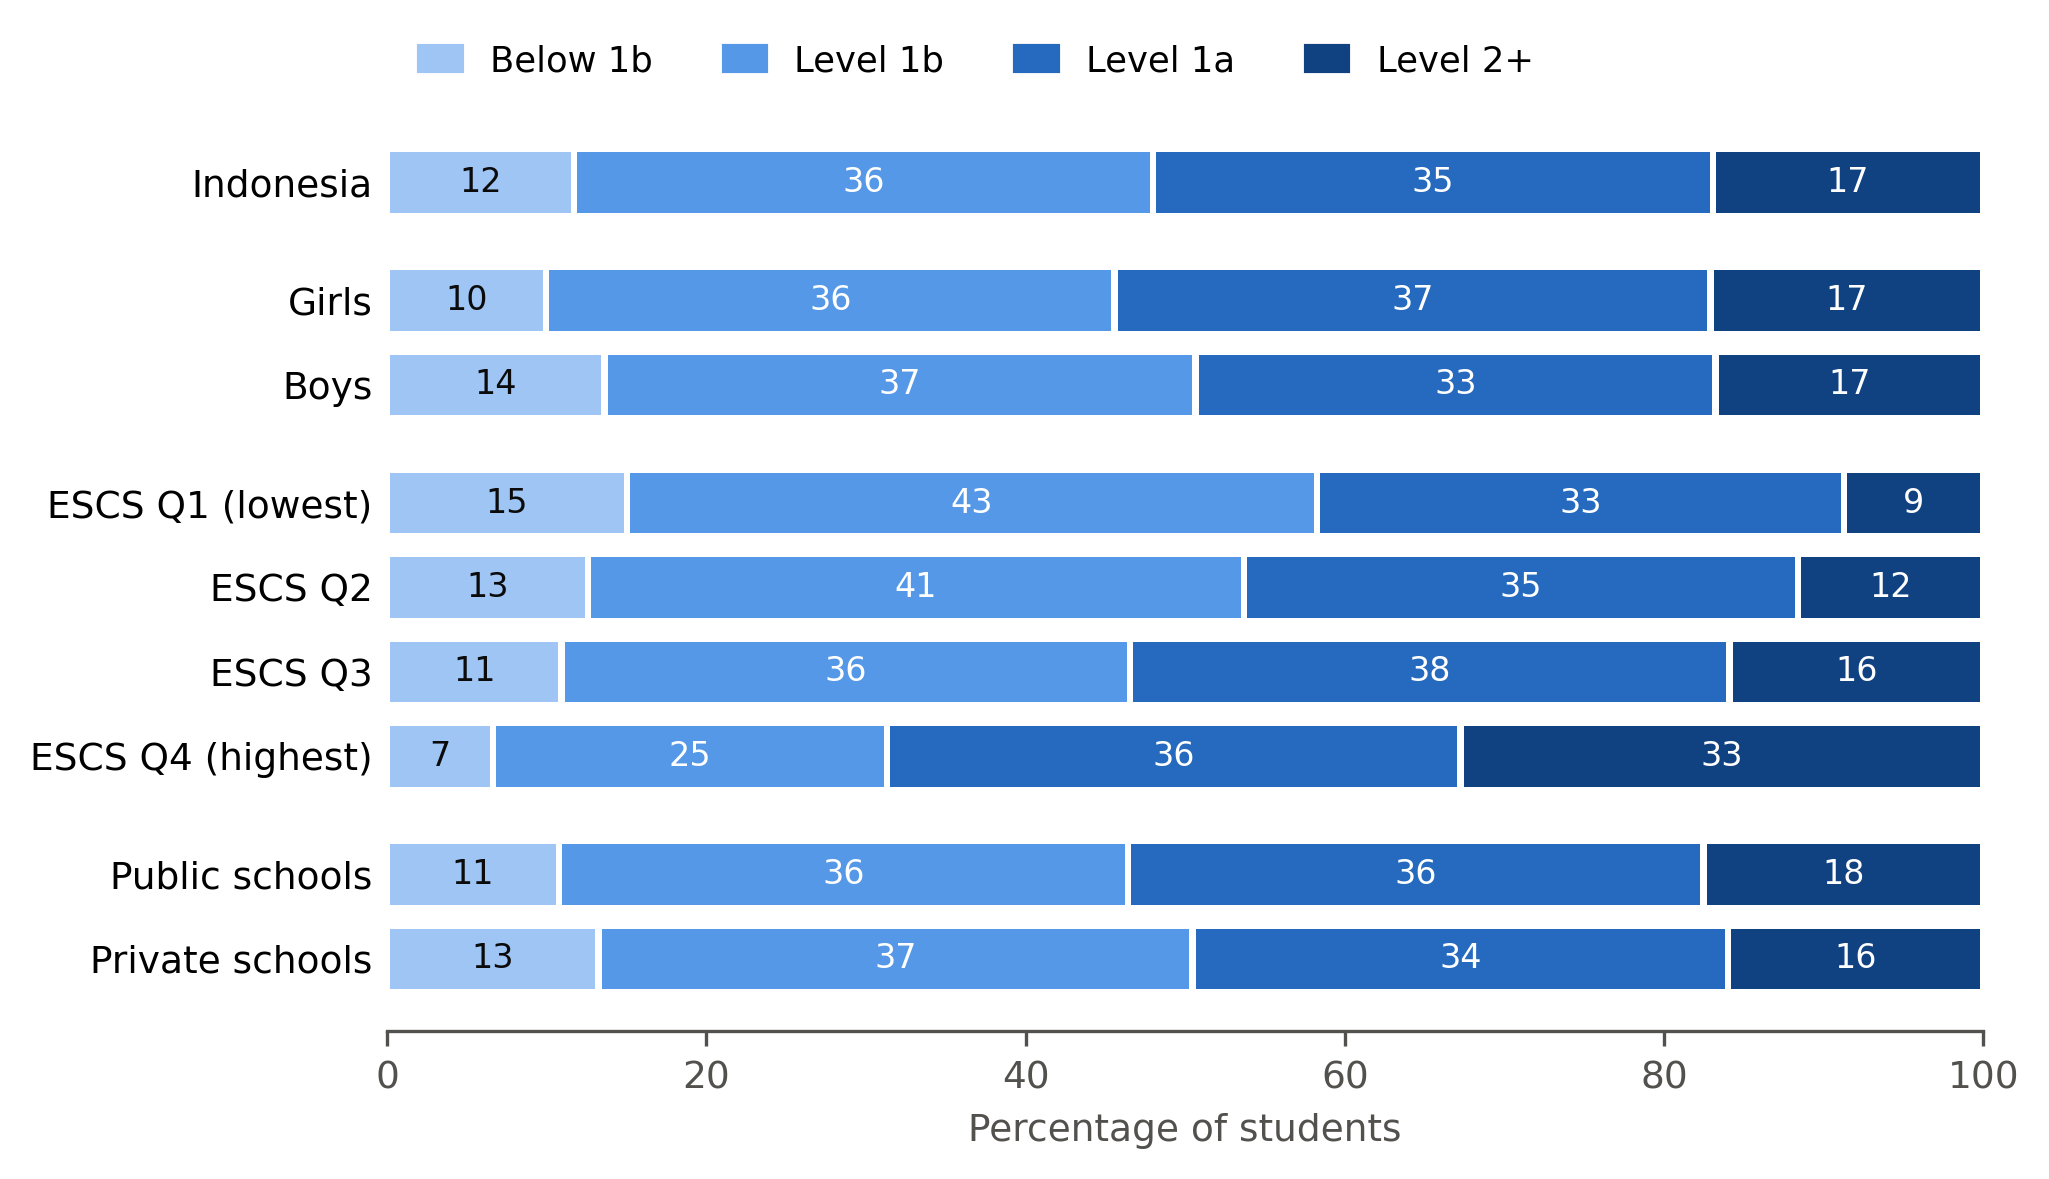

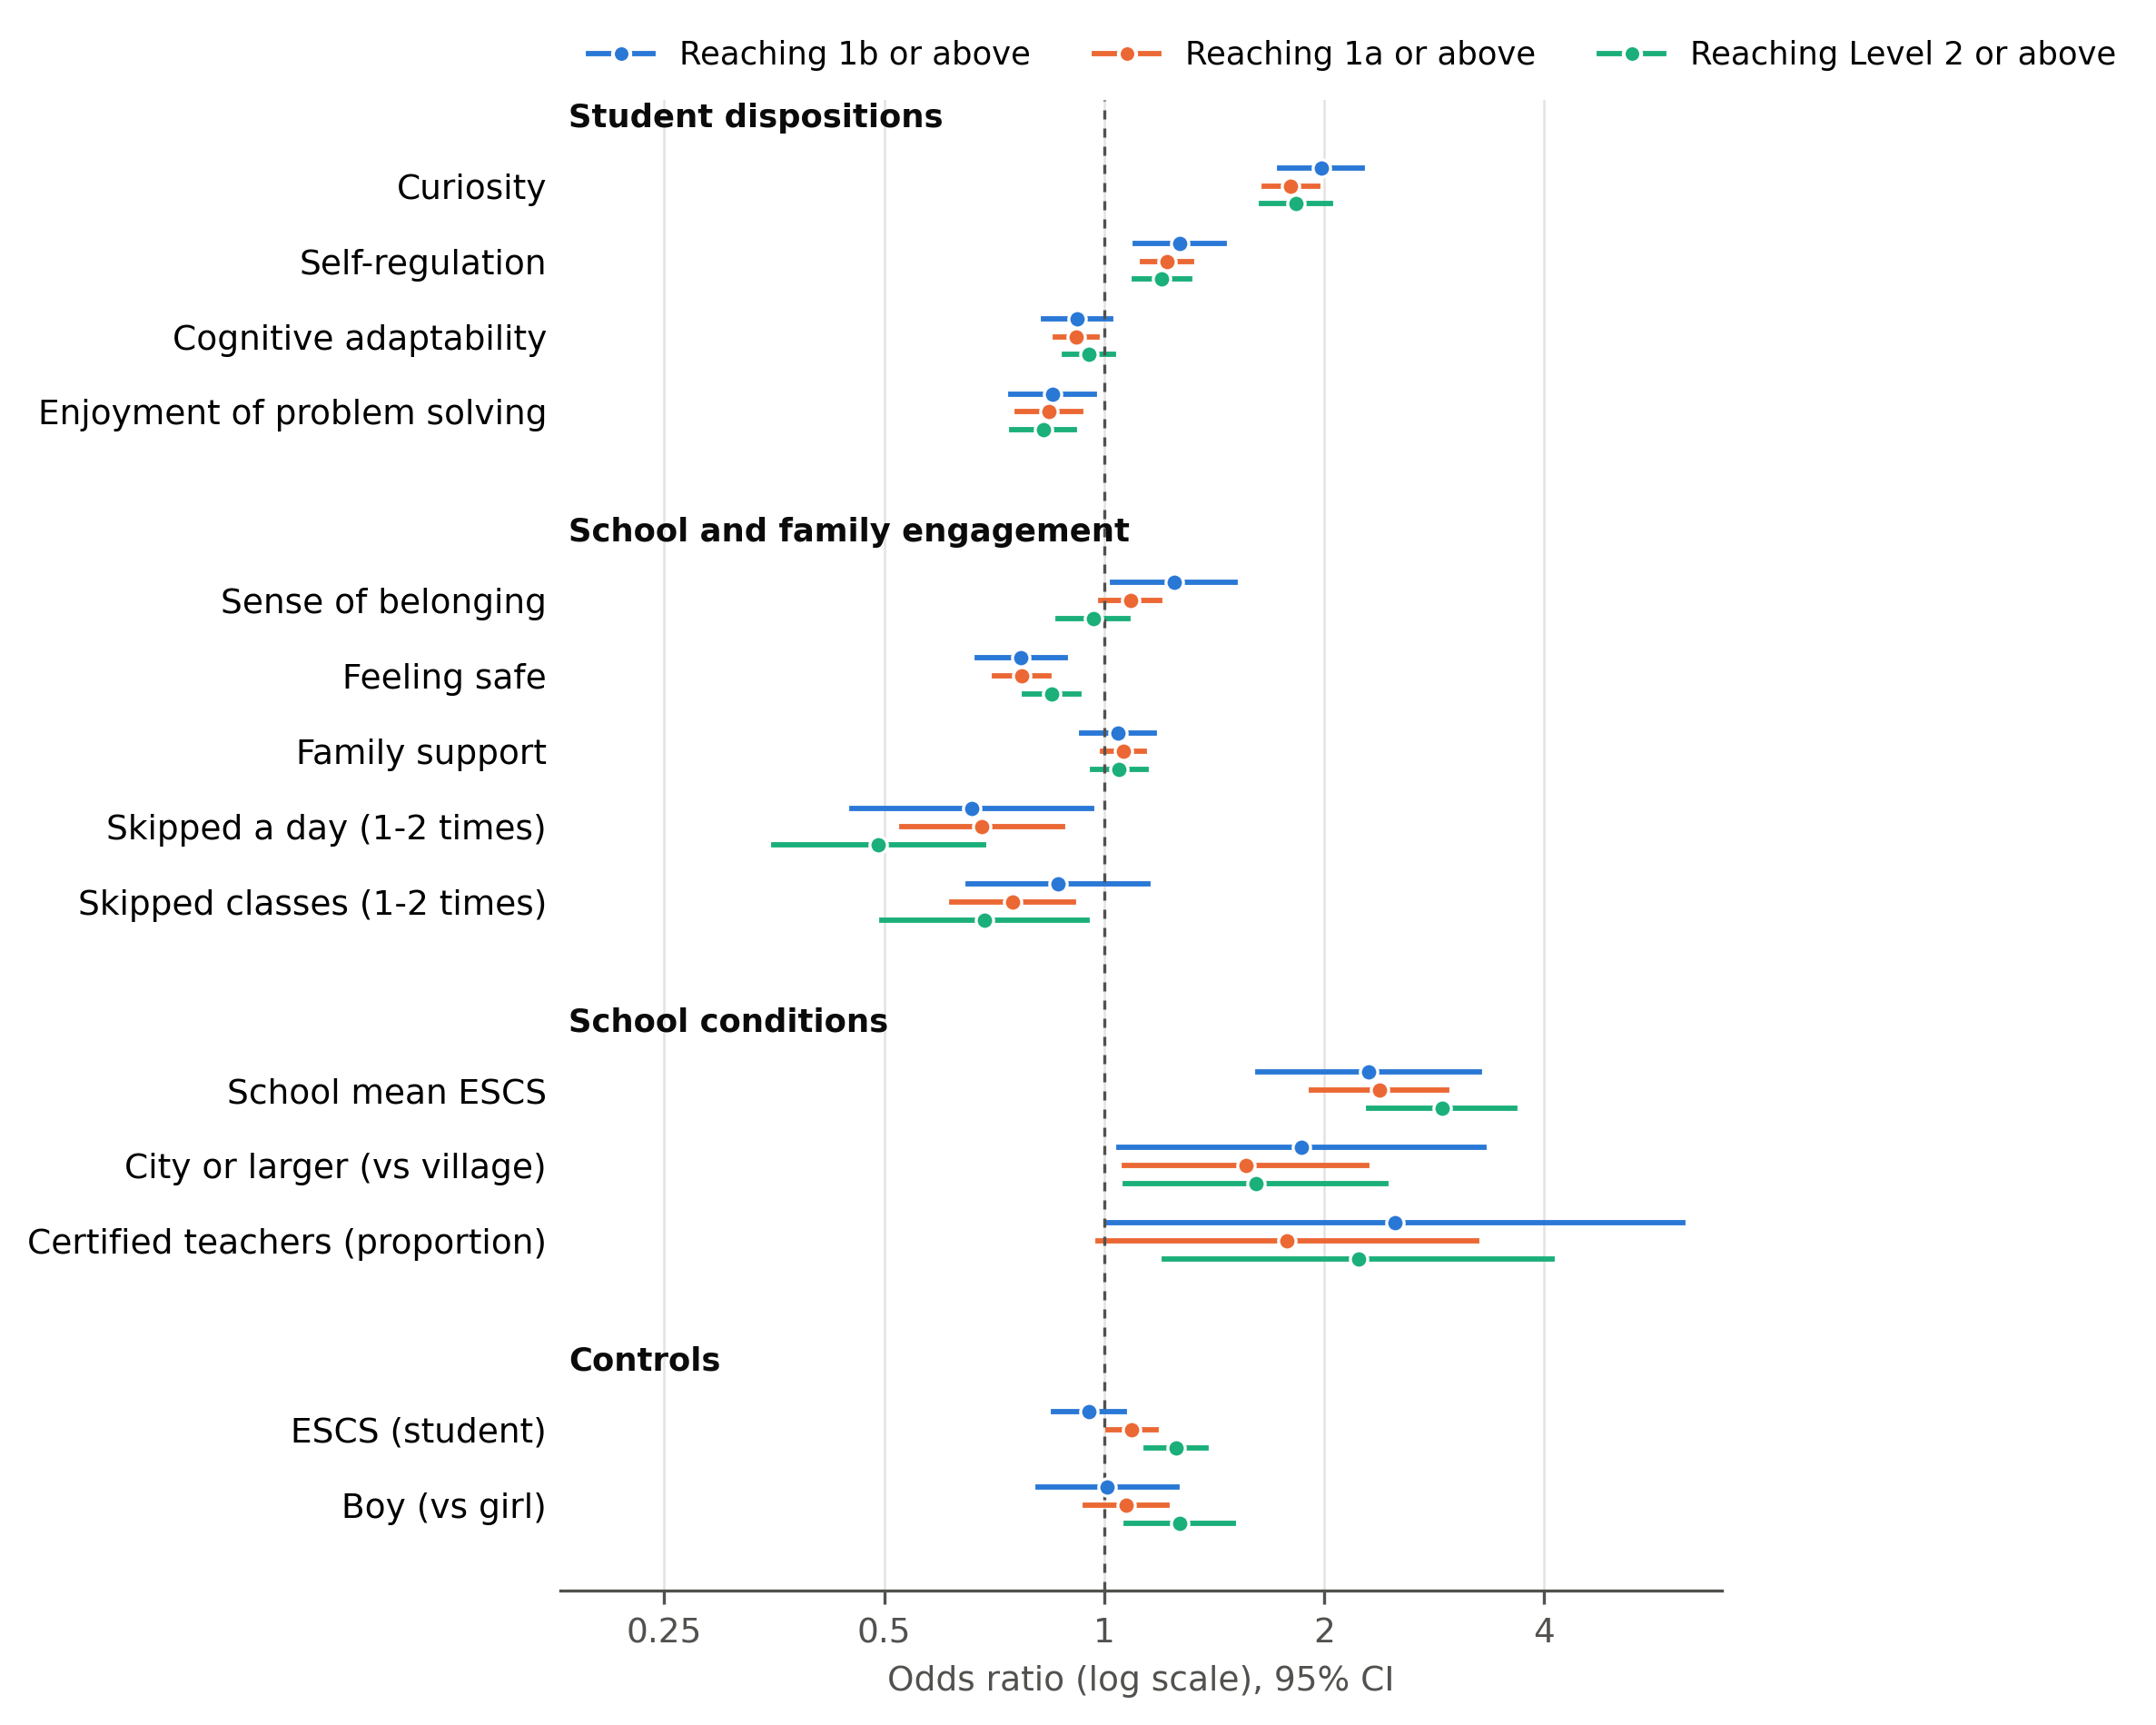

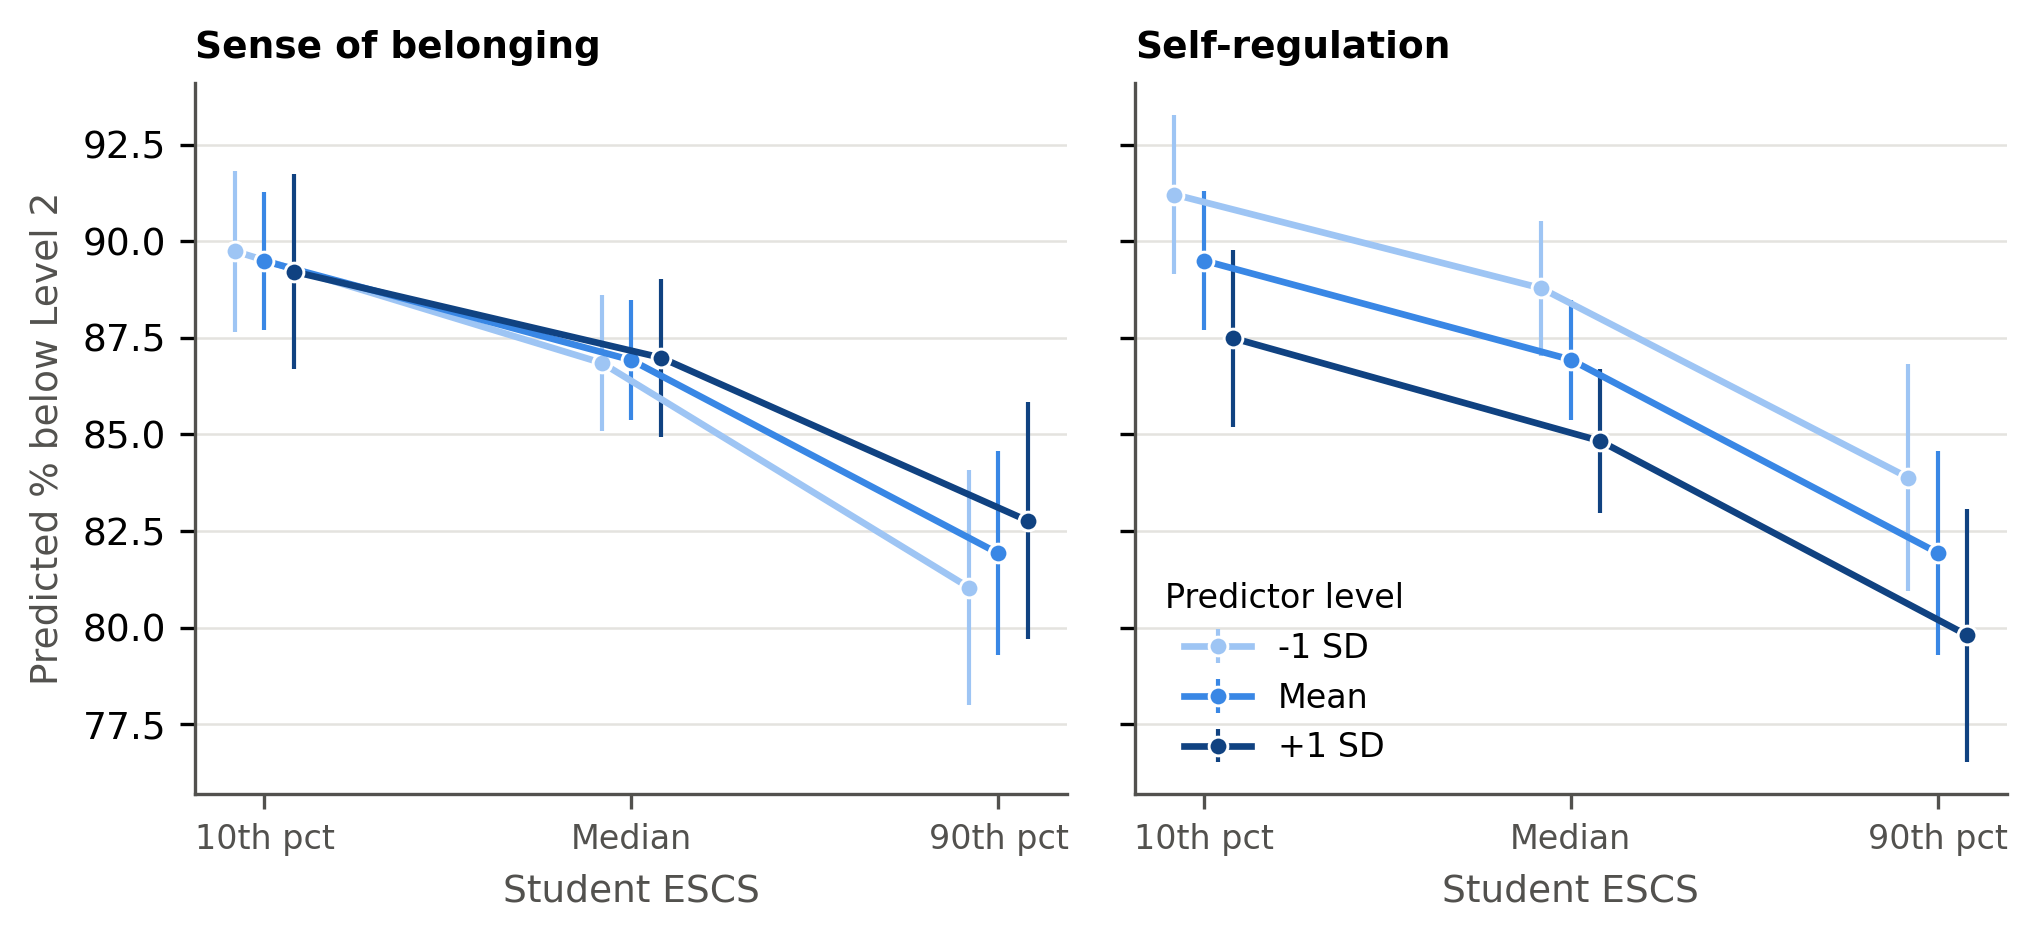

In [ ]:
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': '#52514e', 'xtick.color': '#52514e', 'axes.linewidth': 0.8})
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
SEQ = ['#9ec5f4', '#5598e7', '#256abf', '#104281']
CAT3 = ['#2a78d6', '#eb6834', '#1baf7a']

# Figure 2: proficiency levels by group
order_g = [g for g, _ in GROUPS]; ypos = [0, 1.4, 2.4, 3.8, 4.8, 5.8, 6.8, 8.2, 9.2]
fig, ax = plt.subplots(figsize=(6.9, 4.0), dpi=300)
for yi, (g, r) in zip(ypos, fig2_data.loc[order_g].iterrows()):
    left = 0
    for k, c in enumerate(CATS):
        v = r[c]; ax.barh(yi, v - 0.4, left=left + 0.2, height=0.72, color=SEQ[k], edgecolor='none')
        if v >= 5:
            ax.text(left + v / 2, yi, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if k >= 1 else INK)
        left += v
ax.set_yticks(ypos, order_g); ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel('Percentage of students', color=MUTED)
for sp in ['top', 'right', 'left']: ax.spines[sp].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=SEQ[k]) for k in range(4)], CATS, ncol=4, frameon=False,
          loc='lower left', bbox_to_anchor=(0, 1.0), fontsize=8.5, handlelength=1.2)
fig.tight_layout(); fig.savefig(f'{OUTDIR}/Figure2_levels_by_group.png', bbox_inches='tight'); plt.show()

# Figure 3: odds ratios by threshold
keys = ['CURIO', 'SELFREG', 'COGABIL', 'ENPROBS', 'BELONG', 'FEELSAFE', 'FAMSUP', 'SKIP_DAY_1-2x',
        'SKIP_CLASS_1-2x', 'SCH_ESCS', 'LOC_CITY', 'CERT_TEACH', 'ESCS', 'MALE']
blocks_of = {k: b for b, ks in [('Student dispositions', DISP), ('School and family engagement', ['BELONG', 'FEELSAFE', 'FAMSUP', 'SKIP_DAY_1-2x', 'SKIP_CLASS_1-2x']),
                                ('School conditions', ['SCH_ESCS'] + SCHOOL), ('Controls', ['ESCS', 'MALE'])] for k in ks}
short = {'SKIP_DAY_1-2x': 'Skipped a day (1-2 times)', 'SKIP_CLASS_1-2x': 'Skipped classes (1-2 times)',
         'LOC_CITY': 'City or larger (vs village)', 'CERT_TEACH': 'Certified teachers (proportion)', 'MALE': 'Boy (vs girl)'}
fig, ax = plt.subplots(figsize=(6.9, 6.4), dpi=300); y = 0; yt, yl, blocks, prev = [], [], [], None
for k in keys:
    if blocks_of[k] != prev:
        if prev is not None: y += 0.6
        blocks.append((y, blocks_of[k])); y += 0.9; prev = blocks_of[k]
    for i, (_, lab) in enumerate(THR):
        r = res_thr[lab].set_index('Term').loc[k]; yy = y + (i - 1) * 0.24
        ax.plot([r.OR_CI_low, r.OR_CI_high], [yy, yy], color=CAT3[i], lw=1.4)
        ax.plot(r.OR, yy, 'o', ms=4.6, color=CAT3[i], mec='white', mew=0.8, zorder=3)
    yt.append(y); yl.append(short.get(k, LABELS[k])); y += 1
ax.set_xscale('log'); ax.set_xticks([0.25, 0.5, 1, 2, 4], ['0.25', '0.5', '1', '2', '4']); ax.minorticks_off()
ax.set_xlim(0.18, 7); ax.axvline(1, color=MUTED, lw=0.8, ls=(0, (3, 3)))
ax.set_yticks(yt, yl); ax.invert_yaxis(); ax.tick_params(axis='y', length=0)
for yb, b in blocks: ax.text(0.185, yb, b, fontsize=8.5, fontweight='bold', color=INK, va='center')
for sp in ['top', 'right', 'left']: ax.spines[sp].set_visible(False)
ax.grid(axis='x', color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel('Odds ratio (log scale), 95% CI', color=MUTED)
ax.legend([plt.Line2D([], [], color=CAT3[i], marker='o', lw=1.4, ms=4.6, mec='white') for i in range(3)],
          [lab for _, lab in THR], ncol=3, frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0), fontsize=8.5)
fig.tight_layout(); fig.savefig(f'{OUTDIR}/Figure3_threshold_forest.png', bbox_inches='tight'); plt.show()

# Figure 4: predicted percentages below Level 2
fig, axs = plt.subplots(1, 2, figsize=(6.9, 3.2), dpi=300, sharey=True)
cols = ['#9ec5f4', '#3987e5', '#104281']
for ax, foc, ttl in zip(axs, ['BELONG', 'SELFREG'], ['Sense of belonging', 'Self-regulation']):
    dd_ = pred[pred.Predictor == foc]; xs = list(escs_pts); xn = np.arange(len(xs))
    for i, l in enumerate(['-1 SD', 'Mean', '+1 SD']):
        s_ = dd_[dd_.Level == l].set_index('ESCS').loc[xs]
        ax.errorbar(xn + (i - 1) * 0.08, s_.Pct_below_L2, yerr=1.96 * s_.SE, color=cols[i], marker='o', ms=4.5, lw=1.6,
                    elinewidth=1, mec='white', mew=0.7, label=l)
    ax.set_xticks(xn, xs, fontsize=8); ax.set_title(ttl, fontsize=9, loc='left', fontweight='bold')
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True); ax.set_xlabel('Student ESCS', color=MUTED)
axs[0].set_ylabel('Predicted % below Level 2', color=MUTED)
axs[1].legend(title='Predictor level', frameon=False, fontsize=8, title_fontsize=8, loc='lower left')
fig.tight_layout(); fig.savefig(f'{OUTDIR}/Figure4_predicted_probabilities.png', bbox_inches='tight'); plt.show()

## 14. Export

All tables are written to `outputs/Results_PISA2025_Indonesia.xlsx` (one sheet per table). Download the `outputs/` folder from the Colab file browser, or copy it to Google Drive.

In [ ]:
xlsx = f'{OUTDIR}/Results_PISA2025_Indonesia.xlsx'
with pd.ExcelWriter(xlsx) as xw:
    rq1.round(2).to_excel(xw, sheet_name='RQ1 levels by group', index=False)
    rq1_diff.round(2).to_excel(xw, sheet_name='RQ1 differences', index=False)
    table1.round(2).to_excel(xw, sheet_name='Table 1', index=False)
    table2.to_excel(xw, sheet_name='Table 2', index=False)
    table3.round(4).to_excel(xw, sheet_name='Table 3', index=False)
    thrtest.round(4).to_excel(xw, sheet_name='Threshold tests (all)', index=False)
    tableA1.to_excel(xw, sheet_name='Table A1 robustness', index=False)
    res_int.round(4).to_excel(xw, sheet_name='Table A2 interactions', index=False)
    pred.round(2).to_excel(xw, sheet_name='Figure 4 data', index=False)
    tableA5.round(3).to_excel(xw, sheet_name='Table A5 marginal effects', index=False)
    tableA6.round(3).to_excel(xw, sheet_name='Table A6 two-level', index=False)
    vif.round(3).to_excel(xw, sheet_name='Table A7a VIF', index=False)
    supp.to_excel(xw, sheet_name='Table A7b suppression', index=False)
    glob_test.round(4).to_excel(xw, sheet_name='Table A7c global PO test', index=False)
    cur_int.round(4).reset_index().to_excel(xw, sheet_name='Table A7d curiosity x ESCS', index=False)
    pd.DataFrame({'Statistic': ['ICC(1) of ESCS', 'n0 (students per school)', 'Reliability ICC(2) of school mean ESCS',
                                'ICC empty two-level model', 'Residual ICC full two-level model'],
                  'Value': [icc1, n0, icc2, np.mean(icc_0), np.mean(icc_c)]}).round(3).to_excel(xw, sheet_name='Clustering stats', index=False)
    diag.round(3).to_excel(xw, sheet_name='Table A3 imputation', index=False)
    for name, r_ in [('Full ordinal', res_ord)] + [(f'Full {lab[:22]}', r_) for lab, r_ in res_thr.items()]:
        r_.round(4).to_excel(xw, sheet_name=name[:31], index=False)
print('Saved', xlsx)
print('Total run time: %.1f minutes' % ((time.time() - T0) / 60))

Saved outputs/Results_PISA2025_Indonesia.xlsx
Total run time: 17.3 minutes
